# 02 · What drives global trait space? XGBoost + SHAP with environmentally and spatially separated cross-validation

This notebook follows Mahecha et al. (2021, *Ecography*), with two changes: XGBoost replaces random forest, and SHAP values replace random-forest variable importance.

**Targets:** the trait PCs per H3 res-3 cell, and optionally other per-cell columns such as the community-mean CSR scores (`TARGET_COLS`), in three modes:

- **present**: all species
- **native**: native species only
- **shift**: present − native, for the trait PCs, and its length ‖shift‖: how far the whole present-day community has moved away from the native community in trait space. Both share one PCA rotation, so the difference is meaningful.
- **intro_share** and **delta**: the shift split into its two parts (section 1). p is the share of introduced species ("how many aliens"); Δ is the distance in trait space between the introduced and the native species ("how different they are"). Both are one value per cell.

**Predictors** (`MODEL`, one run per model):

- **model "env":** PCA of climate (4 PCs) and PCA of soil (4 PCs)
- **model "env+human":** the same, plus human pressure (log population density, cropland and urban cover) and data quality (log records per cell, trait missingness)

Section 8 compares the two models on the same cells and folds.

**Cross-validation:** affinity propagation on an asymmetric similarity matrix. The lower triangle holds similarity in trait space and the upper triangle holds geographic proximity, which gives folds that are both spatially contiguous and environmentally distinct. Each fold is left out in turn.

**Inputs** (same folder as this notebook):

- your trait CSV (long format: `h3_res3`, `group` ∈ {all, native}, `PC1…PC5`, `count`, …)
- `env_data/env_predictors_h3r3.csv` from notebook 01

**Outputs:** everything is written to `results_trait_env/`, with figures in `results_trait_env/figures/`.

In [1]:
# %pip install numpy pandas scipy scikit-learn xgboost matplotlib pyarrow   # once, if missing (cartopy optional, for coastlines)
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from scipy.spatial.distance import cdist
from scipy.stats import spearmanr
from sklearn.cluster import AffinityPropagation
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False

# Test cartopy once. The land outlines are downloaded on first use, which fails on nodes without internet;
# in that case (or any other cartopy problem) fall back to plain lon/lat maps.
if HAS_CARTOPY:
    try:
        _f = plt.figure()
        _a = _f.add_subplot(projection=ccrs.EqualEarth())
        _a._autoscaleXon = True; _a._autoscaleYon = True     # same workaround as in your other map code
        _a.add_feature(cfeature.LAND, facecolor="#e4e3df", edgecolor="none")
        _a.scatter([0], [0], transform=ccrs.PlateCarree())
        _f.canvas.draw()
    except Exception as e:
        print(f"cartopy cannot draw maps here ({type(e).__name__}: {str(e)[:120]}); maps are drawn as plain lon/lat plots.")
        HAS_CARTOPY = False
    finally:
        plt.close("all")

print("xgboost", xgb.__version__, "| cartopy:", HAS_CARTOPY)

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


xgboost 2.1.4 | cartopy: True


## Settings
Everything you might want to change lives in this one cell.

In [2]:
# --- Which model ------------------------------------------------------------------
# Run the notebook once per model. Each run writes into its own folder (OUT_DIR below ends in MODEL).
#   "env":       climate + soil only                                                    (model 1)
#   "env+human": + human pressure (population density, cropland, urban cover)
#                + data quality (records per cell, trait missingness)                  (model 2)
#   "custom":    use the USE_... switches further down as they are
MODEL = "env+human"   # "env", "env+human" or "custom"

# --- Inputs / outputs -----------------------------------------------------------
TRAIT_CSV   = Path("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10_notrim_misstree_group_with_CSR.csv")
ENV_PATTERN = "env_predictors_h3r3*.csv"

ENV_DIR = Path("~/Func_Neo_Phytes/Data/env_data").expanduser()

OUT_DIR     = Path("~/Func_Neo_Phytes/Results/trait_env/").expanduser() / MODEL     # e.g. Path("~/Func_Neo_Phytes/Results/trait_env").expanduser() / MODEL
FIG_DIR     = Path("~/Func_Neo_Phytes/Results/Figures/trait_env/").expanduser() / MODEL
OUT_CSV = Path("~/Func_Neo_Phytes/Data/env_data/env_predictors_h3r3.csv").expanduser()

OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

# --- What to model --------------------------------------------------------------
MODES     = ["present", "native", "shift", "intro_share"]   # add "delta" for Δ (how different the introduced species are)
TARGET_COLS = ["PC1", "PC2", "PC3", "C", "S", "R"]
# what to model: trait PCs (PC1 size, PC2 leaf economics, PC3 turnover) and/or any other per-cell column of
# the trait file, e.g. the CSR scores. Names are matched to the file's columns (also "C_mean", "CSR_C", …);
# the notebook prints which column it used. Only the CSR scores: TARGET_COLS = ["C", "S", "R"]

# --- Shift and its decomposition (modes "shift", "intro_share", "delta") ---------
SHIFT_PCS = ["PC1", "PC2", "PC3"]   # trait PCs used for the shift and for Δ (CSR scores are only modelled for present/native)
SHIFT_LENGTH = True     # model ‖shift‖: distance in trait space (SHIFT_PCS) between the present and the native community
SHIFT_PER_PC = True     # also model the signed shift of each PC (in which direction the community moved)
INTRO_SHARE_FROM = "records"   # p from species counts (count_sp; right if the trait means are taken over species)
                               # or "records" (count; if the trait means are weighted by occurrence records)
DELTA_MIN_INTRO  = 1           # Δ only in cells with at least this many introduced species (noisy otherwise)
DELTA_PER_PC     = False       # False: Δ is one value per cell, the trait-space distance between introduced and natives
                               # True:  also model Δ separately per PC (in which direction the introduced species differ)

# --- Predictors -----------------------------------------------------------------
N_ENV_PCS    = 4        # PCs kept per block (climate, soil), as in Mahecha et al.
CLIMATE_SET  = "bio_summaries"   # "bio_summaries": 19 BIO + annual mean & seasonality (CV) of srad, wind, vapr (25 vars)
                                 # "all_monthly":   all 103 WorldClim layers as in Mahecha et al. (calendar months!)
CLIMATE_EXTRAS = False  # True: also add rain–light synchrony and number of dry months (seasonality, see section 2)
USE_POP      = True     # human pressure: log10(pop density + 1)
USE_LANDCOVER = True    # human pressure: land-cover fractions (the classes in LANDCOVER_CLASSES)
LANDCOVER_CLASSES = ["crop", "urban"]   # columns lu_frac_<class> to use; None = all classes in the env file
USE_RECORDS  = True     # data quality: log10(records + 1) per cell (records of the modelled group)
USE_MISSINGNESS = True  # data quality: the cell's mean trait missingness
if MODEL == "env":
    USE_POP = USE_LANDCOVER = USE_RECORDS = USE_MISSINGNESS = False
elif MODEL == "env+human":
    USE_POP = USE_LANDCOVER = USE_RECORDS = USE_MISSINGNESS = True
elif MODEL != "custom":
    raise ValueError('MODEL must be "env", "env+human" or "custom"')
GROUP_DATA_SHAP = True  # show records + missingness as one "data quality (combined)" row in the SHAP heatmap
POP_SOURCE = "GPW v4 2020"   # for the methods text
# Life history: share of perennial (or annual) species per cell, from the same occurrence data.
# Note: it is derived from the same assemblages as the trait PCs, so it partly explains them "by construction".
LIFEHISTORY_CSV = None   # e.g. Path("/net/scratch/swolf/GBIF/gbif_h3/aggregated_longevity.csv"); None = not used
LIFEHISTORY_COL = "perennial_percentage"
LANDCOVER_SOURCE = "per-cell land-cover fractions (urban, cropland, natural vegetation, barren, water)"  # for the methods text: add product + year
MAX_BLOCK_NA = 0.5      # drop a cell if more than this share of its climate or soil variables is missing

# --- Spatial folds (affinity propagation) ----------------------------------------
AP_TRAIT_PCS   = ["PC1", "PC2", "PC3", "PC4"]  # "environmental" side of the similarity = present-day trait space
AP_SUBSAMPLE   = 4000   # AP needs several n×n matrices; on a subsample of 4,000 that is ~0.5 GB. None = all cells
AP_PREFERENCE_QUANTILE = 0.0   # 0 = min similarity → fewest clusters; raise (e.g. 0.05) for more folds
AP_DAMPING     = 0.9
MIN_FOLD_SIZE  = 50     # smaller clusters are merged into their most similar neighbour

# --- Model comparison (section 8) -----------------------------------------------------
# Model 2 reuses model 1's folds, so both are tested on exactly the same spatial blocks, and compares its R²
# with model 1's. Both default to the "env" folder next to OUT_DIR; run model "env" first.
REUSE_FOLDS  = OUT_DIR.parent / "env" / "spatial_folds.csv" if MODEL != "env" else None
COMPARE_WITH = OUT_DIR.parent / "env" if MODEL != "env" else None

# --- XGBoost --------------------------------------------------------------------
XGB_PARAMS = dict(
    n_estimators=3000, learning_rate=0.03, max_depth=6, min_child_weight=5,
    subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
    tree_method="hist", n_jobs=-1, random_state=42,
)
EARLY_STOPPING = 100
SEED = 42

OUT_DIR.mkdir(parents=True, exist_ok=True)   # folder for tables, SHAP values, models
FIG_DIR.mkdir(parents=True, exist_ok=True)   # folder for figures (can be anywhere, e.g. your Results/Figures)

In [3]:
# Figure style: light surface, recessive axes; blue/orange/aqua for the three modes,
# one-hue blue for magnitudes, blue↔red around a grey midpoint for signed values.
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
MODE_COLORS = {"present": "#2a78d6", "native": "#eb6834", "shift": "#1baf7a",
               "intro_share": "#8a6d1f", "delta": "#b03a7a"}
MODE_LABELS = {"present": "present", "native": "native", "shift": "shift",
               "intro_share": "share introduced", "delta": "Δ introduced − native"}
SEQ = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f3f7fd", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(
    "div_blue_red", ["#104281", "#3987e5", "#9ec5f4", "#f0efec", "#f3aaa9", "#e34948", "#9e2626"])

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "savefig.dpi": 200, "savefig.bbox": "tight",
})

def savefig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    fig.savefig(FIG_DIR / f"{name}.pdf")

def map_axes(fig, pos):
    if HAS_CARTOPY:
        ax = fig.add_subplot(*pos, projection=ccrs.EqualEarth())
        ax._autoscaleXon = True; ax._autoscaleYon = True   # lets older cartopy (< 0.21) work with newer matplotlib
        ax.set_global()
        ax.add_feature(cfeature.LAND, facecolor=GRID, edgecolor="none", zorder=0)
        return ax, dict(transform=ccrs.PlateCarree())
    ax = fig.add_subplot(*pos)
    ax.set_xlim(-180, 180); ax.set_ylim(-60, 85); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    return ax, {}

## 1 · Trait targets
The trait file has one row per cell and group. It is split into present (`group == "all"`) and native, and the shift is computed as present − native.

**Splitting the shift: how many aliens, and how different.** Each cell's present-day trait mean is a mixture of its native and introduced species: present = (1 − p) × native + p × introduced, where p is the share of introduced species. Subtracting native from both sides gives

> shift = p × Δ, with Δ = introduced mean − native mean

So the same shift can come from a few very different aliens (small p, large Δ) or many similar ones (large p, small Δ). For lengths the same holds: ‖shift‖ = p × Δ. The *community* moves only part of the way towards the introduced species, in proportion to their share. The parts are modelled separately:

- **intro_share** (p): the share of introduced species, 1 − native species / all species (`count_sp`). Expected to follow human pressure.
- **shift · length** (‖shift‖): how far the whole present-day community lies from the native community, the total effect of the introduced species.
- **delta** (Δ): how different the introduced species are, as one value per cell: the Euclidean distance in the space of `SHIFT_PCS` between the mean introduced and the mean native species. The identity also holds for lengths, ‖shift‖ = p × ‖Δ‖, so Δ = ‖shift‖ / p. It is computed only where at least `DELTA_MIN_INTRO` introduced species occur, because dividing by a small p amplifies noise. The distance says *how far* the aliens are from the natives, not in which direction; `DELTA_PER_PC = True` adds Δ per PC for that.

The identity is exact if p is counted the same way as the trait means are averaged: over species (`INTRO_SHARE_FROM = "species"`) for species means, over records for occurrence-weighted means. Using p as a *response* also avoids the circularity of using it as a predictor of the shift.

**CSR scores.** C, S and R are percentages that add up to 100 for every species, and therefore also for a cell mean. Only two of the three are independent: if C and S are known, R follows. The three models are therefore not three separate results. A predictor that raises S must lower C and/or R, and the SHAP patterns mirror each other. Describe them together, e.g. "aridity shifts communities from C towards S". CSR scores are modelled for present and native only; the shift and Δ use the trait PCs (`SHIFT_PCS`).

In [4]:
traits_long = pd.read_csv(TRAIT_CSV).rename(columns={"h3_res3": "h3_index"})
pc_cols = sorted([c for c in traits_long.columns if re.fullmatch(r"PC\d+", c)], key=lambda c: int(c[2:]))

present = traits_long[traits_long["group"] == "all"].set_index("h3_index")
native  = traits_long[traits_long["group"] == "native"].set_index("h3_index")
trait_cells = present.index.intersection(native.index)

def resolve_column(name, columns):
    """Find the trait-file column for a target name: exact, or a common variant such as C_mean, CSR_C, mean_C."""
    if name in columns:
        return name
    n = re.escape(name)
    pattern = rf"(?i)(csr[_.]?)?{n}([_.]?(mean|score|perc|percent|percentage|pct|value|cwm))?|(mean|cwm|csr)[_.]{n}"
    hits = [c for c in columns if re.fullmatch(pattern, c)]
    if len(hits) == 1:
        return hits[0]
    other = [c for c in columns if not re.match(r"X\.X\d+$", c) and c not in ("h3_index", "group")]
    raise KeyError(f"target '{name}': {'several matching columns ' + str(hits) if hits else 'no matching column'} "
                   f"in the trait file. Use the exact column name in TARGET_COLS. Columns (without the X.X trait columns): {other}")

TARGET_SOURCE = {t: resolve_column(t, list(traits_long.columns)) for t in TARGET_COLS}
renamed = {src: t for t, src in TARGET_SOURCE.items() if src != t}
if renamed:
    print("target columns used: " + ", ".join(f"{t} ← {src}" for t, src in TARGET_SOURCE.items() if src != t))

def target_table(df):
    return df.loc[trait_cells, list(TARGET_SOURCE.values())].rename(columns=renamed).apply(pd.to_numeric, errors="coerce")

TARGETS = {"present": target_table(present), "native": target_table(native)}
SHIFT_COLS = [c for c in SHIFT_PCS if c in pc_cols]
assert SHIFT_COLS, f"none of SHIFT_PCS {SHIFT_PCS} is in the trait file ({pc_cols})"
TARGETS["shift"] = (present.loc[trait_cells, SHIFT_COLS].astype(float)
                    - native.loc[trait_cells, SHIFT_COLS].astype(float))

# --- shift = p × Δ ---------------------------------------------------------------
cnt = "count_sp" if INTRO_SHARE_FROM == "species" else "count"
if cnt not in present.columns:
    print(f"⚠ no '{cnt}' column in the trait file; the introduced share is computed from records ('count')")
    cnt = "count"
n_all = present.loc[trait_cells, cnt].astype(float)
n_intro = (n_all - native.loc[trait_cells, cnt].astype(float)).clip(lower=0)
p_intro = (n_intro / n_all).where(n_all > 0)
TARGETS["intro_share"] = pd.DataFrame({"share": p_intro})
delta_pc = TARGETS["shift"].div(p_intro, axis=0)                 # Δ per PC = introduced mean − native mean
delta_pc.loc[(n_intro < DELTA_MIN_INTRO).to_numpy(), :] = np.nan
delta = pd.DataFrame({"distance": np.sqrt((delta_pc ** 2).sum(axis=1, min_count=len(SHIFT_COLS)))})
if DELTA_PER_PC:
    delta = delta_pc.join(delta)
TARGETS["delta"] = delta
shift_len = np.sqrt((TARGETS["shift"] ** 2).sum(axis=1))           # ‖present − native‖ in the space of SHIFT_COLS
TARGETS["shift"] = (TARGETS["shift"] if SHIFT_PER_PC else TARGETS["shift"].iloc[:, :0])
if SHIFT_LENGTH:
    TARGETS["shift"] = TARGETS["shift"].assign(length=shift_len)
assert TARGETS["shift"].shape[1] or "shift" not in MODES, "SHIFT_LENGTH and SHIFT_PER_PC are both False: remove 'shift' from MODES"

unknown = [m for m in MODES if m not in TARGETS]
assert not unknown, f"unknown mode(s) {unknown}; choose from {list(TARGETS)}"
MODE_TARGETS = {m: list(TARGETS[m].columns) if m in ("shift", "intro_share", "delta") else list(TARGET_COLS)
                for m in MODES}
unit = "species" if cnt == "count_sp" else "records"
print(f"share of introduced {unit}: median {p_intro.median():.1%}, 90th percentile {p_intro.quantile(.9):.1%}; "
      f"Δ defined in {(n_intro >= DELTA_MIN_INTRO).sum()} of {len(trait_cells)} cells (≥ {DELTA_MIN_INTRO} introduced {unit})")
if "delta" in MODES:
    print("Spearman ρ between the introduced share and Δ (near 0 = the two parts carry different information):")
    display(pd.Series({t: spearmanr(p_intro, delta[t], nan_policy="omit").correlation for t in delta.columns},
                      name="ρ(p, Δ)").round(2).to_frame().T)

cell_info = pd.DataFrame({"n_records_all": present.loc[trait_cells, "count"],
                          "n_records_native": native.loc[trait_cells, "count"]})
cell_info["n_records_introduced"] = (cell_info["n_records_all"] - cell_info["n_records_native"]).clip(lower=0)
NA_COL = "mean_perc_na" if "mean_perc_na" in present.columns else None
if NA_COL:
    cell_info["missing_all"] = present.loc[trait_cells, NA_COL]
    cell_info["missing_native"] = native.loc[trait_cells, NA_COL]
    cell_info["missing_introduced"] = cell_info["missing_all"]    # no separate value for the introduced species
elif USE_MISSINGNESS:
    print("⚠ no 'mean_perc_na' column in the trait file. Missingness can't be used.")
    USE_MISSINGNESS = False

def group_of(mode):
    """Which group's records / missingness describe a mode's target: native → native, delta → introduced, else all."""
    return {"native": "native", "delta": "introduced"}.get(mode, "all")

print(f"{len(trait_cells)} cells with both present and native values; trait PCs available: {pc_cols}")
zero_shift = (shift_len == 0).mean()
print(f"{zero_shift:.1%} of cells have exactly zero shift (no introduced species recorded)")
for t in TARGET_COLS:
    n_na = TARGETS["present"][t].isna().sum() + TARGETS["native"][t].isna().sum()
    if n_na:
        print(f"{t}: {TARGETS['present'][t].isna().sum()} present / {TARGETS['native'][t].isna().sum()} native cells "
              f"without a value; they are left out of the {t} models only")

CSR = [t for t in ["C", "S", "R"] if t in TARGET_COLS]
if len(CSR) == 3:
    tot = TARGETS["present"][CSR].sum(axis=1, min_count=3).dropna()
    print(f"C + S + R per cell: median {tot.median():.1f}, 1st–99th percentile {tot.quantile(.01):.1f}–{tot.quantile(.99):.1f}")
    if ((tot - tot.median()).abs() < 1).mean() > 0.95:
        print("→ they add up to a constant, so only two of the three are independent (see the note above).")
    display(TARGETS["present"][CSR].corr(method="spearman").round(2))
    print("Spearman correlation of the CSR scores with the trait PCs (present):")
    display(pd.concat([TARGETS["present"][CSR], present.loc[trait_cells, pc_cols[:5]]], axis=1)
            .corr(method="spearman").loc[CSR, pc_cols[:5]].round(2))
pd.concat({m: TARGETS[m][MODE_TARGETS[m]].describe().T[["count", "mean", "std", "min", "max"]] for m in MODES}).round(3)

share of introduced records: median 11.0%, 90th percentile 41.7%; Δ defined in 7394 of 9752 cells (≥ 1 introduced records)
9752 cells with both present and native values; trait PCs available: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5']
18.9% of cells have exactly zero shift (no introduced species recorded)
C + S + R per cell: median 100.0, 1st–99th percentile 100.0–100.0
→ they add up to a constant, so only two of the three are independent (see the note above).


,C,S,R
C,1.00,-0.58,-0.02
S,-0.58,1.00,-0.74
R,-0.02,-0.74,1.00


Spearman correlation of the CSR scores with the trait PCs (present):


,PC1,PC2,PC3,PC4,PC5
C,0.74,0.47,0.02,-0.07,-0.14
S,-0.08,-0.93,-0.08,0.04,0.09
R,-0.47,0.78,0.07,-0.06,-0.01


count    mean     std     min      max
present     PC1     9752.0  -0.025   3.592 -13.106   16.905
            PC2     9752.0   0.128   2.482 -13.190   12.831
            PC3     9752.0  -0.099   1.681 -11.272    8.890
            C       9752.0  23.575  10.145   0.000  100.000
            S       9752.0  50.751  16.395   0.000  100.000
            R       9752.0  25.674  13.370   0.000  100.000
native      PC1     9752.0   0.025   3.749 -13.096   16.949
            PC2     9752.0  -0.128   2.606 -13.196   12.819
            PC3     9752.0   0.099   1.771 -11.245    8.939
            C       9752.0  23.668  10.946   0.000  100.000
            S       9752.0  52.145  17.184   0.000  100.000
            R       9752.0  24.187  13.881   0.000   99.564
shift       PC1     9752.0  -0.050   0.900 -11.924   14.307
            PC2     9752.0   0.255   0.684 -10.623    8.467
            PC3     9752.0  -0.199   0.490  -8.418    5.272
            length  9752.0   0.739   1.039   0.000   14.341
intro_share share   9752.0   0.161   0.171   0.000    0.875

## 2 · Environmental predictors
The notebook-01 CSVs are read in, and climate and soil are each reduced to `N_ENV_PCS` principal components on standardised variables. Population density is log-transformed. Land-cover fractions go in as they are: there are only a few, they are bounded in [0, 1], and they are directly interpretable.

**Climate set (`CLIMATE_SET`).** The monthly WorldClim layers are calendar months, so "July" is summer in the north and winter in the south. In a global PCA those layers partly encode the hemisphere rather than the climate. The default `"bio_summaries"` avoids this. It uses the 19 bioclimatic variables, which are defined relative to each place's own seasons (e.g. "warmest quarter"), plus the annual mean and seasonality (coefficient of variation over the 12 months) of solar radiation, wind speed and water vapour pressure. That gives 25 variables, each with a plain meaning. `"all_monthly"` uses all 103 layers, as Mahecha et al. did for Germany, where the problem doesn't arise.

**Optional seasonality extras (`CLIMATE_EXTRAS = True`).** These are two more variables, also independent of hemisphere:
- **Rain–light synchrony:** the correlation of the 12 monthly precipitation and radiation values. +1 means it rains in the bright season (summer rain or monsoon); −1 means it rains in the dark season (Mediterranean-type).
- **Number of dry months:** months where precipitation in mm is below twice the mean temperature in °C (the Walter–Lieth rule).

In [5]:
env_files = sorted(ENV_DIR.glob(ENV_PATTERN))
assert env_files, f"No files matching {ENV_DIR}/{ENV_PATTERN}. Run notebook 01 first."
env = (pd.concat([pd.read_csv(f) for f in env_files])
         .drop_duplicates("h3_index").set_index("h3_index"))

def monthly(var):
    """12 monthly WorldClim values of one variable per cell, as an (n_cells, 12) array."""
    cols = [f"wc_{var}_{m:02d}" for m in range(1, 13)]
    missing = [c for c in cols if c not in env.columns]
    if missing:
        raise KeyError(f"monthly WorldClim columns missing from the env file, e.g. {missing[:3]}")
    return env[cols].to_numpy(dtype=float)

if CLIMATE_SET == "bio_summaries":
    clim = env[[f"wc_bio{i:02d}" for i in range(1, 20)]].copy()
    with np.errstate(invalid="ignore", divide="ignore"):
        for var in ["srad", "wind", "vapr"]:
            m = monthly(var)
            clim[f"wc_{var}_mean"] = m.mean(axis=1)
            clim[f"wc_{var}_cv"] = m.std(axis=1) / m.mean(axis=1)
        if CLIMATE_EXTRAS:
            P, S, T = monthly("prec"), monthly("srad"), monthly("tavg")
            Pc, Sc = P - P.mean(axis=1, keepdims=True), S - S.mean(axis=1, keepdims=True)
            clim["wc_rain_light_sync"] = (Pc * Sc).sum(axis=1) / np.sqrt((Pc ** 2).sum(axis=1) * (Sc ** 2).sum(axis=1))
            clim["wc_dry_months"] = (P < 2 * T).sum(axis=1).astype(float)
    env = env.drop(columns=[c for c in env.columns if c.startswith("wc_")]).join(clim)
elif CLIMATE_SET != "all_monthly":
    raise ValueError('CLIMATE_SET must be "bio_summaries" or "all_monthly"')
# extra climate layers from notebook 01 (e.g. aridity index, PET) join the climate block in either set
cx_cols = [c for c in env.columns if c.startswith("cx_")]
env = env.rename(columns={c: "wc_" + c[3:] for c in cx_cols})
print(f"climate set: {CLIMATE_SET}" + (" + seasonality extras" if CLIMATE_SET == "bio_summaries" and CLIMATE_EXTRAS else "")
      + (f" + {', '.join(c[3:] for c in cx_cols)}" if cx_cols else ""))

wc_cols = [c for c in env.columns if c.startswith("wc_")]
sg_cols = [c for c in env.columns if c.startswith("sg_")]
lu_cols = [c for c in env.columns if c.startswith("lu_frac_")]
if LANDCOVER_CLASSES is not None:
    lu_cols = [c for c in lu_cols if c.replace("lu_frac_", "") in LANDCOVER_CLASSES]
    if USE_LANDCOVER and len(lu_cols) < len(LANDCOVER_CLASSES):
        print(f"⚠ land-cover classes not found: {sorted(set(LANDCOVER_CLASSES) - {c[8:] for c in lu_cols})}; "
              f"available: {[c[8:] for c in env.columns if c.startswith('lu_frac_')]}")
print(f"{len(env_files)} file(s), {len(env)} cells | climate {len(wc_cols)} vars, soil {len(sg_cols)} vars, "
      f"land cover {len(lu_cols)} classes, population: {'pop_density' in env.columns}")

na_wc, na_sg = env[wc_cols].isna().mean(axis=1), env[sg_cols].isna().mean(axis=1)
keep = (na_wc <= MAX_BLOCK_NA) & (na_sg <= MAX_BLOCK_NA)
print(f"dropping {(~keep).sum()} cells with >{MAX_BLOCK_NA:.0%} missing climate or soil values "
      f"(typically ice, tiny islands, coast-only cells)")
env = env[keep]

climate set: bio_summaries + aridity_index
1 file(s), 9752 cells | climate 26 vars, soil 78 vars, land cover 2 classes, population: True
dropping 141 cells with >50% missing climate or soil values (typically ice, tiny islands, coast-only cells)


In [6]:
def block_pca(df, cols, n, label):
    """Standardise, impute medians, PCA. Loadings are correlations between variables and PCs."""
    n = min(n, len(cols))                      # in case a block has very few variables
    X = df[cols].astype(float)
    X = X.fillna(X.median())
    Z = StandardScaler().fit_transform(X)
    pca = PCA(n_components=n, random_state=SEED).fit(Z)
    names = [f"{label}_PC{i+1}" for i in range(n)]
    scores = pd.DataFrame(pca.transform(Z), index=df.index, columns=names)
    loadings = pd.DataFrame(pca.components_.T * np.sqrt(pca.explained_variance_), index=cols, columns=names)
    return scores, loadings, pca.explained_variance_ratio_

clim_scores, clim_load, clim_var = block_pca(env, wc_cols, N_ENV_PCS, "clim")
soil_scores, soil_load, soil_var = block_pca(env, sg_cols, N_ENV_PCS, "soil")

for name, var in [("climate", clim_var), ("soil", soil_var)]:
    print(f"{name:8s} PCs explain " + ", ".join(f"{v:.0%}" for v in var) + f"  (total {var.sum():.0%})")

BIO_NAMES = {
    "wc_bio01": "annual mean temp", "wc_bio02": "mean diurnal range", "wc_bio03": "isothermality",
    "wc_bio04": "temp seasonality", "wc_bio05": "max temp warmest month", "wc_bio06": "min temp coldest month",
    "wc_bio07": "temp annual range", "wc_bio08": "mean temp wettest quarter", "wc_bio09": "mean temp driest quarter",
    "wc_bio10": "mean temp warmest quarter", "wc_bio11": "mean temp coldest quarter", "wc_bio12": "annual precip",
    "wc_bio13": "precip wettest month", "wc_bio14": "precip driest month", "wc_bio15": "precip seasonality",
    "wc_bio16": "precip wettest quarter", "wc_bio17": "precip driest quarter", "wc_bio18": "precip warmest quarter",
    "wc_bio19": "precip coldest quarter",
    "wc_srad_mean": "radiation, annual mean", "wc_srad_cv": "radiation seasonality",
    "wc_wind_mean": "wind, annual mean", "wc_wind_cv": "wind seasonality",
    "wc_vapr_mean": "vapour pressure, annual mean", "wc_vapr_cv": "vapour pressure seasonality",
    "wc_rain_light_sync": "rain–light synchrony", "wc_dry_months": "number of dry months",
    "wc_aridity_index": "aridity index (P/PET)", "wc_pet_mm": "potential evapotranspiration",
}

def top_loadings(load, k=4):
    """For each PC: the k variables with the strongest correlation, with sign."""
    return pd.DataFrame({pc: [f"{BIO_NAMES.get(v, v)} ({load.loc[v, pc]:+.2f})" for v in load[pc].abs().nlargest(k).index]
                         for pc in load.columns})

display(top_loadings(clim_load))
display(top_loadings(soil_load))

climate  PCs explain 49%, 23%, 8%, 5%  (total 84%)
soil     PCs explain 34%, 22%, 12%, 8%  (total 76%)


,clim_PC1,clim_PC2,clim_PC3,clim_PC4
0,min temp coldest month (+0.96),aridity index (P/PET) (+0.87),"wind, annual mean (-0.58)",precip driest month (+0.43)
1,mean temp coldest quarter (+0.96),precip driest quarter (+0.78),wind seasonality (+0.55),precip driest quarter (+0.42)
2,annual mean temp (+0.94),precip driest month (+0.77),precip seasonality (+0.54),max temp warmest month (+0.36)
3,"vapour pressure, annual mean (+0.93)",mean diurnal range (-0.74),precip wettest month (+0.47),precip seasonality (-0.34)


,soil_PC1,soil_PC2,soil_PC3,soil_PC4
0,sg_wv0033_5-15cm_mean (+0.89),sg_wv1500_60-100cm_mean (-0.86),sg_phh2o_100-200cm_mean (-0.70),sg_silt_0-5cm_mean (-0.48)
1,sg_wv0010_15-30cm_mean (+0.89),sg_wv1500_30-60cm_mean (-0.85),sg_phh2o_60-100cm_mean (-0.69),sg_silt_5-15cm_mean (-0.48)
2,sg_ocd_5-15cm_mean (+0.87),sg_clay_15-30cm_mean (-0.85),sg_phh2o_30-60cm_mean (-0.67),sg_silt_15-30cm_mean (-0.48)
3,sg_ocd_0-5cm_mean (+0.86),sg_sand_60-100cm_mean (+0.84),sg_phh2o_15-30cm_mean (-0.66),sg_silt_30-60cm_mean (-0.47)


Use the two tables above to name the climate and soil axes in the paper, e.g. "clim_PC1 = temperature / seasonality". The PC signs are arbitrary.

### Looking at the environmental PCs
Three figures help name the axes:

1. **Climate loadings:** every climate variable × PC. Each value is the correlation between the variable and the PC; red means the variable increases along the PC, blue means it decreases.
2. **Soil loadings:** one small panel per PC, laid out as property × depth. This shows which soil properties drive each axis, and whether it is a topsoil or subsoil signal.
3. **Maps of the PC scores:** check that each axis matches the geography you'd expect for its name.

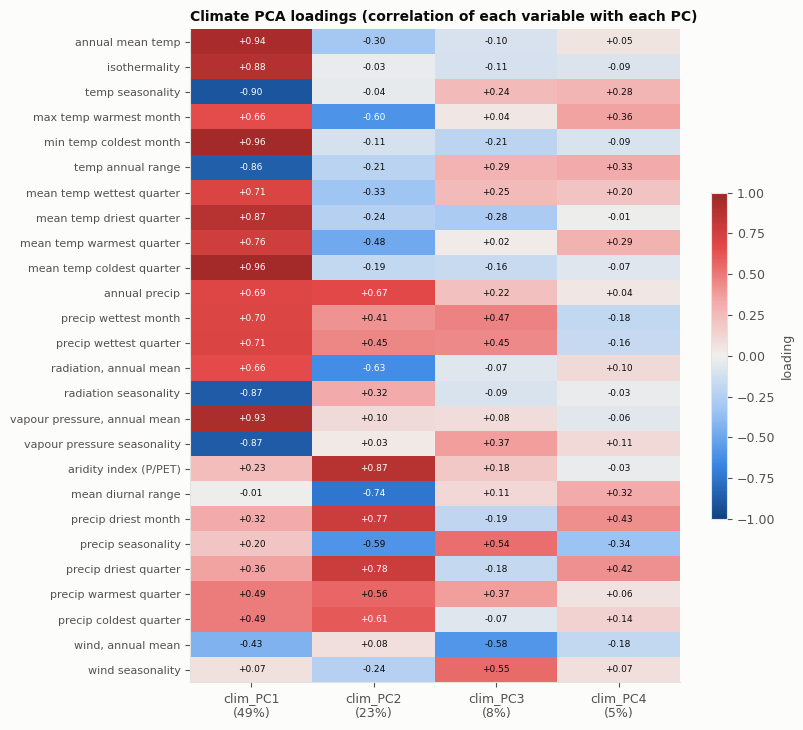

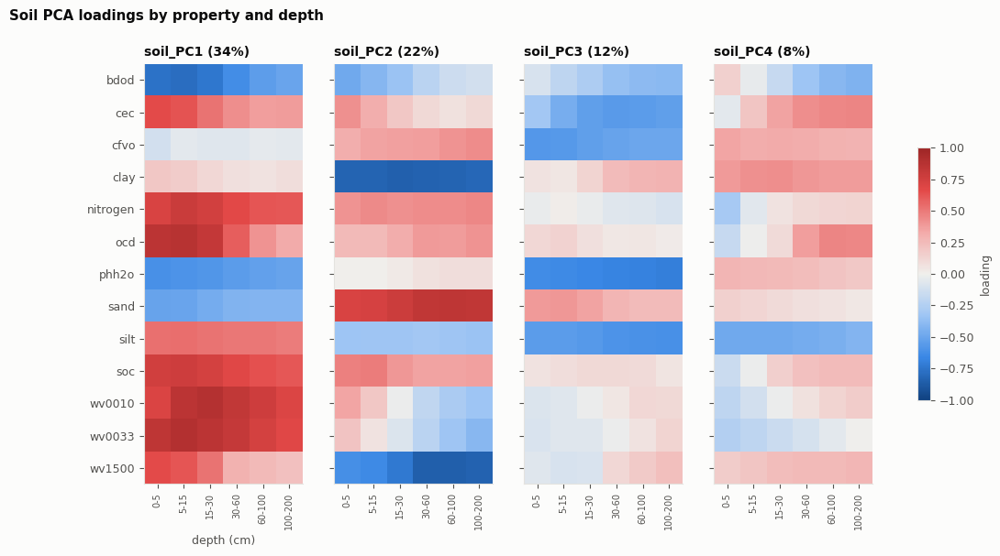

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

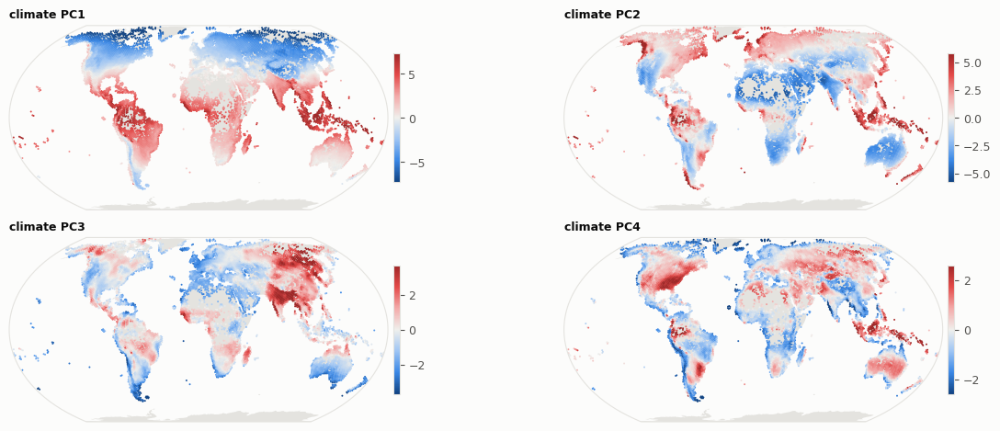

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


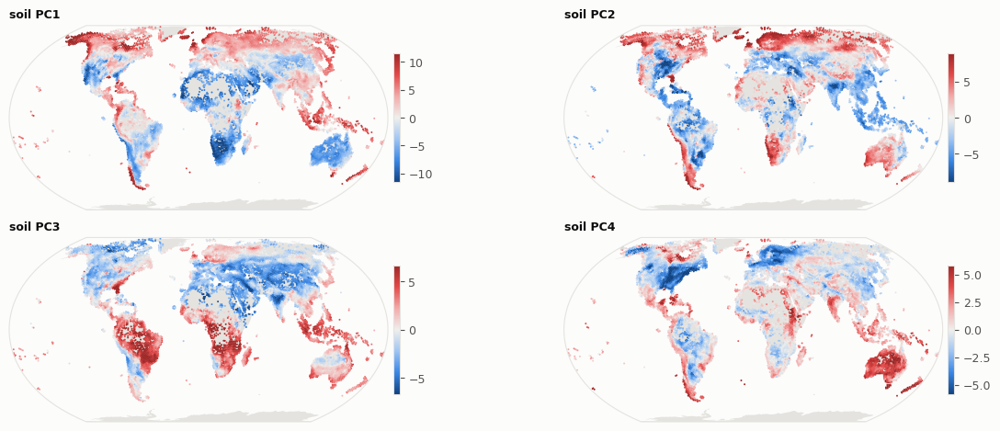

In [7]:
def nice(v):
    return BIO_NAMES.get(v, v)

# 1) climate loadings, all variables
order = clim_load.abs().idxmax(axis=1).map(lambda pc: list(clim_load.columns).index(pc))
cl = clim_load.loc[order.sort_values(kind="stable").index]
fig, ax = plt.subplots(figsize=(1.1 * cl.shape[1] + 3.5, 0.28 * len(cl) + 1.2))
ax.grid(False)
im = ax.imshow(cl.values, cmap=DIV, norm=TwoSlopeNorm(0, -1, 1), aspect="auto")
ax.set_xticks(range(cl.shape[1]), [f"{c}\n({v:.0%})" for c, v in zip(cl.columns, clim_var)])
ax.set_yticks(range(len(cl)), [nice(v) for v in cl.index], fontsize=8)
for (i, j), v in np.ndenumerate(cl.values):
    ax.text(j, i, f"{v:+.2f}", ha="center", va="center", fontsize=6.5, color="white" if abs(v) > 0.6 else INK)
ax.set_title("Climate PCA loadings (correlation of each variable with each PC)", loc="left")
fig.colorbar(im, ax=ax, shrink=0.5, label="loading")
savefig(fig, "00a_climate_pca_loadings")
plt.show()

# 2) soil loadings as property × depth, one panel per PC
DEPTHS = ["0-5cm", "5-15cm", "15-30cm", "30-60cm", "60-100cm", "100-200cm"]
sl = soil_load.copy()
sl["prop"] = [re.sub(r"^sg_|_\d+-\d+cm.*$", "", c) for c in sl.index]
sl["depth"] = [next((d for d in DEPTHS if f"_{d}_" in c or c.endswith(f"_{d}")), "") for c in sl.index]
props = list(dict.fromkeys(sl["prop"]))
fig, axes = plt.subplots(1, soil_load.shape[1], figsize=(3.2 * soil_load.shape[1], 0.32 * len(props) + 1.8),
                         sharey=True, squeeze=False)
for ax, (pc, var) in zip(axes[0], zip(soil_load.columns, soil_var)):
    grid = sl.pivot_table(index="prop", columns="depth", values=pc).reindex(index=props, columns=[d for d in DEPTHS if d in set(sl["depth"])])
    ax.grid(False)
    im = ax.imshow(grid.values, cmap=DIV, norm=TwoSlopeNorm(0, -1, 1), aspect="auto")
    ax.set_xticks(range(grid.shape[1]), [d.replace("cm", "") for d in grid.columns], rotation=90, fontsize=7)
    ax.set_yticks(range(len(props)), props)
    ax.set_title(f"{pc} ({var:.0%})", loc="left")
axes[0, 0].set_xlabel("depth (cm)")
fig.colorbar(im, ax=axes[0], shrink=0.6, label="loading")
fig.suptitle("Soil PCA loadings by property and depth", x=0.01, ha="left", fontweight="bold")
savefig(fig, "00b_soil_pca_loadings")
plt.show()

# 3) maps of the PC scores
env_ll = env.loc[clim_scores.index, ["lat", "lon"]]
for label, scores in [("climate", clim_scores), ("soil", soil_scores)]:
    k = scores.shape[1]
    fig = plt.figure(figsize=(7.5 * min(k, 2), 2.8 * int(np.ceil(k / 2))))
    fig.subplots_adjust(hspace=0.15, wspace=0.08)
    for i, pc in enumerate(scores.columns):
        ax, tf = map_axes(fig, (int(np.ceil(k / 2)), min(k, 2), i + 1))
        v = scores[pc].to_numpy()
        lim = np.nanquantile(np.abs(v), 0.98)
        sc = ax.scatter(env_ll["lon"], env_ll["lat"], c=v, cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim),
                        s=2, linewidths=0, rasterized=True, **tf)
        ax.set_title(f"{label} {pc.split('_')[-1]}", loc="left", fontsize=9)
        fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.01)
    savefig(fig, f"00c_{label}_pc_maps")
    plt.show()

**Biplots.** Each dot is an H3 cell placed by its PC scores and coloured by absolute latitude, so tropical cells are light and polar cells dark. Arrows show the variables. An arrow's direction is where that variable increases, and its length is how strongly it correlates with the two PCs shown.
- **Climate:** every variable gets an arrow. Only the longest ones are labelled, to keep the plot readable. Arrows that point the same way share one label, "name (+n similar)", and the full groups are printed above the plot.
- **Soil:** there are 78 layers, so each arrow is one property averaged over its 6 depths.

Two panels per block: PC1 vs PC2, and PC3 vs PC4.

  clim_PC1/clim_PC2 – similar arrows: annual mean temp, mean temp driest quarter
  clim_PC1/clim_PC2 – similar arrows: mean temp coldest quarter, min temp coldest month
  clim_PC3/clim_PC4 – similar arrows: precip wettest month, precip wettest quarter
  clim_PC3/clim_PC4 – similar arrows: precip driest month, precip driest quarter


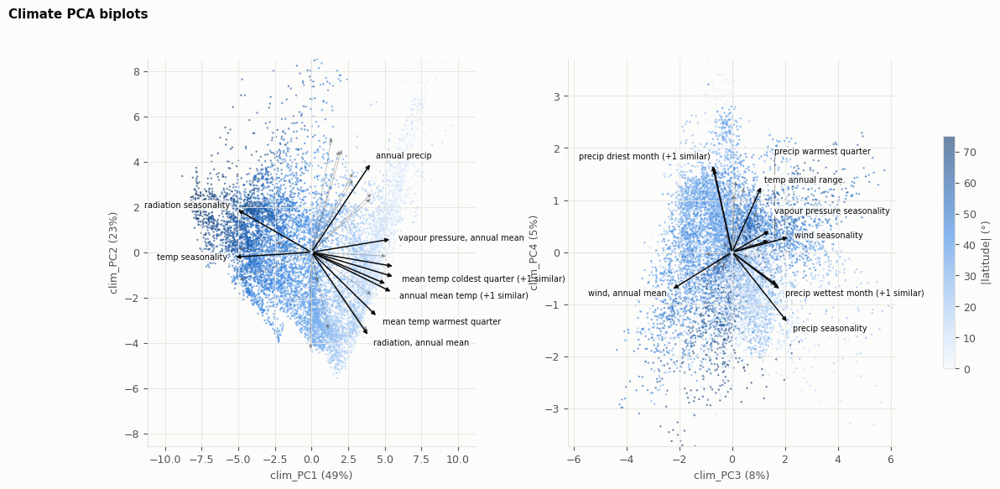

  soil_PC1/soil_PC2 – similar arrows: nitrogen, soc, ocd
  soil_PC1/soil_PC2 – similar arrows: wv0033, wv0010
  soil_PC3/soil_PC4 – similar arrows: cfvo, cec


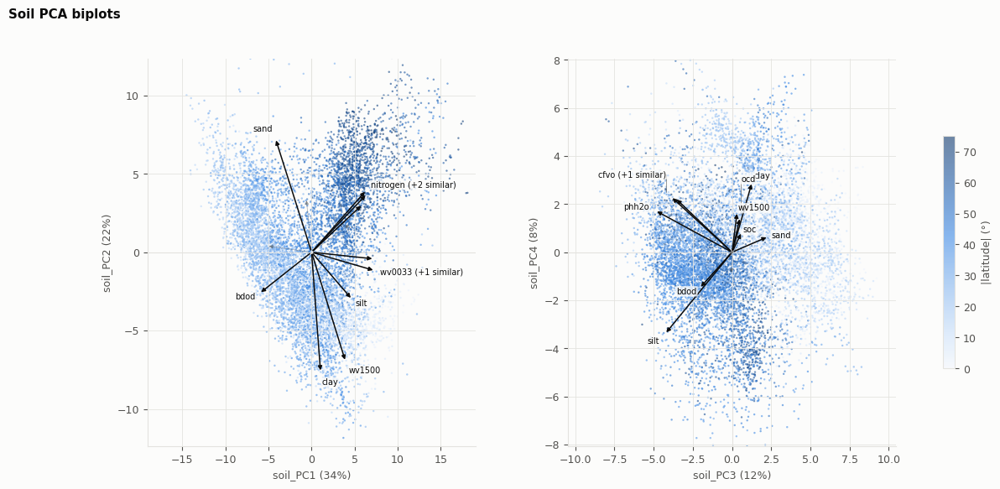

In [8]:
def biplot(ax, scores, load, pcs, names, n_labels=10):
    i, j = pcs
    x, y = scores.iloc[:, i].to_numpy(), scores.iloc[:, j].to_numpy()
    abslat = np.abs(env.loc[scores.index, "lat"].to_numpy())
    sc = ax.scatter(x, y, c=abslat, cmap=SEQ, vmin=0, vmax=75, s=3, linewidths=0, alpha=0.6, rasterized=True)
    L = load.iloc[:, [i, j]].to_numpy()
    length = np.hypot(L[:, 0], L[:, 1])
    rx, ry = np.nanquantile(np.abs(x), 0.99), np.nanquantile(np.abs(y), 0.99)
    scale = 0.85 * min(rx, ry) / max(length.max(), 1e-9)
    # room for points, arrows and labels
    ext_x = max(rx, np.abs(L[:, 0]).max() * scale) * 1.45
    ext_y = max(ry, np.abs(L[:, 1]).max() * scale) * 1.25
    ax.set_xlim(-ext_x, ext_x); ax.set_ylim(-ext_y, ext_y)

    order = np.argsort(length)[::-1]
    labelled = list(order[:n_labels])
    for k in order[::-1]:                                     # draw weak arrows first, strong on top
        strong = k in labelled
        ax.annotate("", xy=(L[k, 0] * scale, L[k, 1] * scale), xytext=(0, 0),
                    arrowprops=dict(arrowstyle="-|>", color=INK if strong else INK2, lw=1.1 if strong else 0.5,
                                    alpha=1 if strong else 0.45, mutation_scale=7))
    # merge labels of arrows that point the same way (within 6° and 15% length): "name (+n similar)"
    groups = []
    for k in labelled:
        ang = np.degrees(np.arctan2(L[k, 1], L[k, 0]))
        for g in groups:
            g_ang = np.degrees(np.arctan2(L[g[0], 1], L[g[0], 0]))
            if abs((ang - g_ang + 180) % 360 - 180) < 6 and abs(length[k] - length[g[0]]) < 0.15 * length[g[0]]:
                g.append(k); break
        else:
            groups.append([k])
    merged = {}
    for g in groups:
        merged[g[0]] = names[g[0]] + (f" (+{len(g) - 1} similar)" if len(g) > 1 else "")
        if len(g) > 1:
            print(f"  {scores.columns[i]}/{scores.columns[j]} – similar arrows: " + ", ".join(names[m] for m in g))

    # labels at the arrow tips, nudged apart vertically if they would overlap (in axes-fraction units)
    placed = []
    for k in merged:
        tx, ty = L[k, 0] * scale * 1.08, L[k, 1] * scale * 1.08
        fx, fy = (tx + ext_x) / (2 * ext_x), (ty + ext_y) / (2 * ext_y)
        # horizontal extent of the label in axes fraction (≈ 0.012 per character at fontsize 7 in these panels)
        width = 0.012 * len(merged[k])
        x0, x1 = (fx, fx + width) if L[k, 0] >= 0 else (fx - width, fx)
        step = 0.045 if fy >= 0.5 else -0.045
        while any(abs(fy - py) < 0.04 and x0 < px1 and px0 < x1 for px0, px1, py in placed):
            fy += step
        fy = float(np.clip(fy, 0.03, 0.97))
        placed.append((x0, x1, fy))
        ax.text(fx, fy, merged[k], transform=ax.transAxes, fontsize=7, color=INK,
                ha="left" if L[k, 0] >= 0 else "right", va="center",
                bbox=dict(boxstyle="round,pad=0.12", fc=SURFACE, ec="none", alpha=0.8))
        if abs(fy - (ty + ext_y) / (2 * ext_y)) > 0.01:      # thin leader line if the label was moved
            ax.plot([tx, tx], [ty, fy * 2 * ext_y - ext_y], color=INK2, lw=0.4)
    ax.axhline(0, color=GRID, lw=0.8, zorder=0); ax.axvline(0, color=GRID, lw=0.8, zorder=0)
    return sc

# soil: one arrow per property (mean loading over its depths)
soil_prop_load = sl.groupby("prop", sort=False)[list(soil_load.columns)].mean()

for label, scores, load, names, var in [
        ("climate", clim_scores, clim_load, [nice(v) for v in clim_load.index], clim_var),
        ("soil", soil_scores, soil_prop_load, list(soil_prop_load.index), soil_var)]:
    pairs = [(0, 1), (2, 3)] if scores.shape[1] >= 4 else [(0, 1)]
    fig, axes = plt.subplots(1, len(pairs), figsize=(7.2 * len(pairs), 6.0), squeeze=False,
                             gridspec_kw=dict(wspace=0.28))
    for ax, (i, j) in zip(axes[0], pairs):
        sc = biplot(ax, scores, load, (i, j), names)
        ax.set_xlabel(f"{scores.columns[i]} ({var[i]:.0%})"); ax.set_ylabel(f"{scores.columns[j]} ({var[j]:.0%})")
    fig.colorbar(sc, ax=axes[0], shrink=0.6, label="|latitude| (°)")
    fig.suptitle(f"{label.capitalize()} PCA biplots", x=0.01, ha="left", fontweight="bold")
    savefig(fig, f"00d_{label}_pca_biplots")
    plt.show()

In [9]:
FEATURES = pd.concat([clim_scores, soil_scores], axis=1)
if USE_POP:
    FEATURES["log_pop_density"] = np.log10(env.loc[FEATURES.index, "pop_density"].clip(lower=0) + 1)
    pop_missing = FEATURES["log_pop_density"].isna()
    print(f"dropping {pop_missing.sum()} cells without a population value")
    FEATURES = FEATURES[~pop_missing]
if USE_LANDCOVER:
    FEATURES = FEATURES.join(env.loc[FEATURES.index, lu_cols])
    lu_missing = FEATURES[lu_cols].isna().any(axis=1)
    print(f"dropping {lu_missing.sum()} cells without land-cover values (not in the table, or almost all water)")
    FEATURES = FEATURES[~lu_missing]

LH_COL = None
if LIFEHISTORY_CSV is not None:
    lh = pd.read_csv(Path(LIFEHISTORY_CSV).expanduser(), sep=None, engine="python")
    lh = lh.loc[:, ~lh.columns.str.startswith("Unnamed")]
    lh_id = next(c for c in lh.columns if "h3" in c.lower())
    lh[lh_id] = lh[lh_id].astype(str)
    LH_COL = "lh_" + LIFEHISTORY_COL
    FEATURES[LH_COL] = lh.groupby(lh_id)[LIFEHISTORY_COL].mean().reindex(FEATURES.index).to_numpy()
    lh_missing = FEATURES[LH_COL].isna()
    print(f"life history: {LIFEHISTORY_COL} from {Path(LIFEHISTORY_CSV).name}; "
          f"dropping {lh_missing.sum()} cells without a value")
    FEATURES = FEATURES[~lh_missing]

# keep only cells that have both traits and predictors
CELLS = FEATURES.index.intersection(trait_cells)
FEATURES = FEATURES.loc[CELLS]
LAT, LON = env.loc[CELLS, "lat"].to_numpy(), env.loc[CELLS, "lon"].to_numpy()

PRETTY = {"log_pop_density": "log pop. density"}
PRETTY.update({c: f"climate PC{c[-1]}" for c in clim_scores.columns})
PRETTY.update({c: f"soil PC{c[-1]}" for c in soil_scores.columns})
LU_NAMES = {"crop": "cropland", "nat": "natural veg.", "water": "water (share of cell)"}
PRETTY.update({c: LU_NAMES.get(c.replace("lu_frac_", ""), c.replace("lu_frac_", "")) + " cover" for c in lu_cols})
PRETTY.update({"log_records": "log records (sampling)", "trait_missingness": "trait missingness",
               "data quality (combined)": "data quality (records + missingness)"})
if LH_COL:
    PRETTY[LH_COL] = "% " + LIFEHISTORY_COL.replace("_percentage", "").replace("_", " ") + " species"
pretty = lambda c: PRETTY.get(c, c)

print(f"modelling {len(CELLS)} cells × {FEATURES.shape[1]} predictors: {list(FEATURES.columns)}")
extra = (["log_records"] if USE_RECORDS else []) + (["trait_missingness"] if USE_MISSINGNESS else [])
if extra:
    print(f"+ per mode (records/missingness of the modelled group: native → native, present & shift → all): {extra}")

if LH_COL:   # how much the life-history share overlaps with the targets themselves
    rho = pd.DataFrame({m: {pc: spearmanr(FEATURES[LH_COL], TARGETS[m].loc[CELLS, pc], nan_policy="omit").correlation for pc in MODE_TARGETS[m]}
                        for m in MODES}).round(2)
    print(f"\nSpearman correlation of {pretty(LH_COL)} with the trait PCs (|ρ| > 0.6 = strong overlap, "
          f"i.e. the predictor largely restates the target):")
    display(rho)

dropping 4 cells without a population value
dropping 123 cells without land-cover values (not in the table, or almost all water)
modelling 9484 cells × 11 predictors: ['clim_PC1', 'clim_PC2', 'clim_PC3', 'clim_PC4', 'soil_PC1', 'soil_PC2', 'soil_PC3', 'soil_PC4', 'log_pop_density', 'lu_frac_urban', 'lu_frac_crop']
+ per mode (records/missingness of the modelled group: native → native, present & shift → all): ['log_records', 'trait_missingness']


## 3 · Spatial folds: affinity propagation on an asymmetric similarity matrix
As in Mahecha et al., the lower triangle of the similarity matrix is the negative Euclidean distance in the target space. Here that is the leading present-day trait PCs (Mahecha et al. used Isomap dimensions). The upper triangle is the negative great-circle distance. Both are divided by their median, so neither dominates.

Affinity propagation picks the number of clusters itself. It is run on a random subsample (`AP_SUBSAMPLE`) to keep memory manageable, and the remaining cells join the most similar exemplar. Clusters smaller than `MIN_FOLD_SIZE` are merged into their closest neighbour.

In [10]:
def haversine_km(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    dlat = lat2[None, :] - lat1[:, None]
    dlon = lon2[None, :] - lon1[:, None]
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1)[:, None] * np.cos(lat2)[None, :] * np.sin(dlon / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))

REUSING = REUSE_FOLDS is not None and Path(REUSE_FOLDS).expanduser().exists()
if REUSE_FOLDS is not None and not REUSING:
    print(f"no fold file at {REUSE_FOLDS}: running affinity propagation. "
          "Run model 'env' first if both models should share their folds.")
if REUSING:
    fold_file = pd.read_csv(Path(REUSE_FOLDS).expanduser(), dtype={"h3_index": str}).set_index("h3_index")["fold"]
    in_file = CELLS.isin(fold_file.index)
    if (~in_file).any():
        print(f"{(~in_file).sum()} cells are not in the fold file and are left out")
    CELLS = CELLS[in_file]
    FEATURES = FEATURES.loc[CELLS]
    LAT, LON = env.loc[CELLS, "lat"].to_numpy(), env.loc[CELLS, "lon"].to_numpy()
    print(f"reusing the folds of {REUSE_FOLDS} for {len(CELLS)} cells")

F_ap = present.loc[CELLS, AP_TRAIT_PCS].to_numpy(dtype=float)   # trait PCs, also when only CSR is modelled
n = len(CELLS)
if not REUSING:
    rng = np.random.default_rng(SEED)
    sub = np.sort(rng.choice(n, AP_SUBSAMPLE, replace=False)) if AP_SUBSAMPLE and n > AP_SUBSAMPLE else np.arange(n)

    D_env = cdist(F_ap[sub], F_ap[sub])
    D_geo = haversine_km(LAT[sub], LON[sub], LAT[sub], LON[sub])
    iu = np.triu_indices(len(sub), 1)
    s_env, s_geo = np.median(D_env[iu]), np.median(D_geo[iu])

    lower = np.tril(np.ones_like(D_env, dtype=bool), -1)
    S = np.where(lower, -D_env / s_env, -D_geo / s_geo)        # asymmetric similarity
    preference = np.quantile(S[~np.eye(len(sub), dtype=bool)], AP_PREFERENCE_QUANTILE)
    del D_env, D_geo

    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        ap = AffinityPropagation(affinity="precomputed", preference=preference, damping=AP_DAMPING,
                                 max_iter=3000, convergence_iter=100, random_state=SEED).fit(S)
        if any("did not converge" in str(x.message) for x in w):
            print("⚠ affinity propagation did not converge. Try AP_DAMPING = 0.95.")
    del S
    exemplars = sub[ap.cluster_centers_indices_]
    print(f"affinity propagation found {len(exemplars)} clusters on {len(sub)} cells")

reusing the folds of /net/home/swolf/Func_Neo_Phytes/Results/trait_env/env/spatial_folds.csv for 9484 cells


In [11]:
def combined_similarity(i_idx, j_idx):
    """Symmetric version (mean of both triangles) used to attach the remaining cells and merge small clusters."""
    de = cdist(F_ap[i_idx], F_ap[j_idx]) / s_env
    dg = haversine_km(LAT[i_idx], LON[i_idx], LAT[j_idx], LON[j_idx]) / s_geo
    return -(de + dg) / 2

if REUSING:
    _, FOLDS = np.unique(fold_file.loc[CELLS].to_numpy(), return_inverse=True)
else:
    folds = np.argmax(combined_similarity(np.arange(n), exemplars), axis=1)
    folds[sub] = ap.labels_                       # subsampled cells keep their AP label

    # merge clusters that are too small to be a meaningful test set
    while True:
        sizes = np.bincount(folds, minlength=len(exemplars))
        alive = np.flatnonzero(sizes)
        small = [k for k in alive if sizes[k] < MIN_FOLD_SIZE]
        if not small or len(alive) <= 2:
            break
        k = min(small, key=lambda c: sizes[c])
        others = [c for c in alive if c != k]
        target = others[int(np.argmax(combined_similarity([exemplars[k]], exemplars[others])[0]))]
        folds[folds == k] = target

    _, FOLDS = np.unique(folds, return_inverse=True)  # relabel 0..K-1
N_FOLDS = FOLDS.max() + 1
sizes = np.bincount(FOLDS)
print(f"{N_FOLDS} folds after merging; cells per fold: min {sizes.min()}, median {int(np.median(sizes))}, max {sizes.max()}")
pd.DataFrame({"h3_index": CELLS, "fold": FOLDS, "lat": LAT, "lon": LON}).to_csv(OUT_DIR / "spatial_folds.csv", index=False)

41 folds after merging; cells per fold: min 72, median 215, max 482


/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

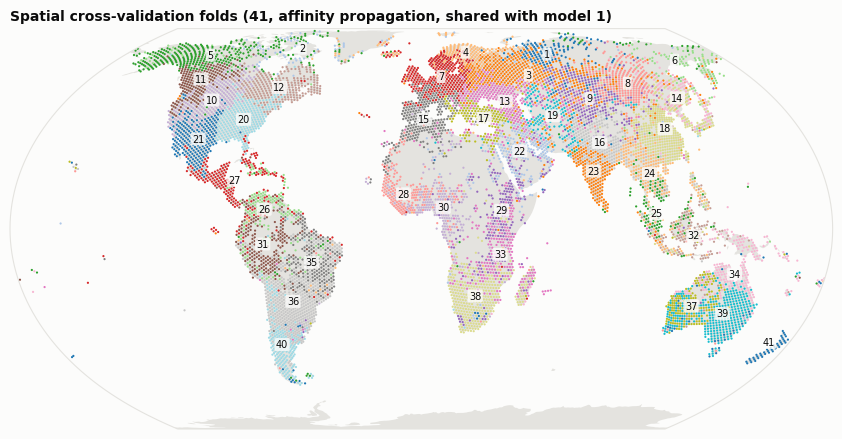

In [12]:
fig = plt.figure(figsize=(11, 5.2))
ax, tf = map_axes(fig, (1, 1, 1))
# Many folds → colour only separates neighbours; every fold is also labelled with its number.
fold_colors = plt.get_cmap("tab20")(np.arange(N_FOLDS) % 20)
ax.scatter(LON, LAT, c=fold_colors[FOLDS], s=2.5, linewidths=0, **tf)
for k in range(N_FOLDS):
    m = FOLDS == k
    ax.text(np.median(LON[m]), np.median(LAT[m]), str(k + 1), fontsize=7, ha="center", va="center",
            color=INK, bbox=dict(boxstyle="round,pad=0.15", fc=SURFACE, ec="none", alpha=0.8), **tf)
ax.set_title(f"Spatial cross-validation folds ({N_FOLDS}, affinity propagation"
             + (", shared with model 1" if REUSING else "") + ")", loc="left")
savefig(fig, "00_spatial_folds")
plt.show()

## 4 · XGBoost with leave-one-fold-out cross-validation
For each mode and each target:

1. **Cross-validation.** Each fold is left out once. Inside the training data, a held-out 15% of folds is used for early stopping. The out-of-fold predictions give the honest R².
2. **Final model.** A model is fitted on all cells, with as many trees as the median early-stopping point. SHAP values come from this model, using exact TreeSHAP via `pred_contribs`, so the `shap` package isn't needed.

Runtime grows with folds × modes × PCs. On a laptop, expect roughly 5–20 minutes.

In [13]:
def spatial_cv(X, y, folds):
    oof = np.full(len(y), np.nan)
    best_iters, fold_r2 = [], []
    inner = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
    for k in np.unique(folds):
        test = folds == k
        tr = np.flatnonzero(~test)
        fit_i, stop_i = next(inner.split(tr, groups=folds[tr]))
        model = xgb.XGBRegressor(**XGB_PARAMS, early_stopping_rounds=EARLY_STOPPING)
        model.fit(X.iloc[tr[fit_i]], y[tr[fit_i]],
                  eval_set=[(X.iloc[tr[stop_i]], y[tr[stop_i]])], verbose=False)
        oof[test] = model.predict(X.iloc[test])
        best_iters.append(model.best_iteration + 1)
        if test.sum() > 1:
            fold_r2.append(r2_score(y[test], oof[test]))
    return oof, best_iters, fold_r2

def fit_final(X, y, n_trees):
    params = {**XGB_PARAMS, "n_estimators": int(n_trees)}
    model = xgb.XGBRegressor(**params).fit(X, y, verbose=False)
    contrib = model.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
    shap_df = pd.DataFrame(contrib[:, :-1], index=X.index, columns=X.columns)
    return model, shap_df, contrib[0, -1]

def design_matrix(mode):
    """Shared predictors + the mode-specific sampling covariates (records / missingness of the modelled group)."""
    X = FEATURES.copy()
    g = group_of(mode)
    if USE_RECORDS:
        X["log_records"] = np.log10(cell_info.loc[CELLS, f"n_records_{g}"].to_numpy() + 1)
    if USE_MISSINGNESS:
        X["trait_missingness"] = cell_info.loc[CELLS, f"missing_{g}"].to_numpy()
    return X

RESULTS = {}
for mode in MODES:
    X = design_matrix(mode)
    for pc in MODE_TARGETS[mode]:
        y_all = TARGETS[mode].loc[CELLS, pc].to_numpy(dtype=float)
        ok = np.isfinite(y_all)                  # cells with a value for this target (e.g. Δ needs enough introduced species)
        Xm, y = X[ok], y_all[ok]
        oof, iters, fold_r2 = spatial_cv(Xm, y, FOLDS[ok])
        n_trees = max(int(np.median(iters)), 10)
        model, shap_df, base = fit_final(Xm, y, n_trees)
        RESULTS[(mode, pc)] = dict(
            X=Xm, y=y, ok=ok, oof=oof, shap=shap_df, base=base, model=model, n_trees=n_trees,
            r2=r2_score(y, oof), rmse=np.sqrt(mean_squared_error(y, oof)),
            fold_r2=np.array(fold_r2),
            r2_train=r2_score(y, model.predict(Xm)),
        )
        r = RESULTS[(mode, pc)]
        print(f"{mode:11s} {pc:>8s}:  CV R² = {r['r2']:.3f}   (RMSE {r['rmse']:.3f}, "
              f"median fold R² {np.median(r['fold_r2']):.2f}, {n_trees} trees, train R² {r['r2_train']:.2f}"
              + (f", {(~ok).sum()} cells without a value" if (~ok).any() else "") + ")")

present          PC1:  CV R² = 0.635   (RMSE 2.141, median fold R² -0.14, 136 trees, train R² 0.79)
present          PC2:  CV R² = 0.427   (RMSE 1.882, median fold R² 0.07, 90 trees, train R² 0.63)
present          PC3:  CV R² = 0.326   (RMSE 1.383, median fold R² 0.06, 61 trees, train R² 0.50)
present            C:  CV R² = 0.518   (RMSE 6.957, median fold R² 0.04, 134 trees, train R² 0.72)
present            S:  CV R² = 0.425   (RMSE 12.423, median fold R² 0.06, 122 trees, train R² 0.66)
present            R:  CV R² = 0.371   (RMSE 10.507, median fold R² -0.06, 98 trees, train R² 0.59)
native           PC1:  CV R² = 0.629   (RMSE 2.257, median fold R² -0.13, 124 trees, train R² 0.78)
native           PC2:  CV R² = 0.423   (RMSE 1.983, median fold R² 0.04, 92 trees, train R² 0.63)
native           PC3:  CV R² = 0.342   (RMSE 1.439, median fold R² 0.06, 82 trees, train R² 0.54)
native             C:  CV R² = 0.527   (RMSE 7.453, median fold R² 0.10, 112 trees, train R² 0.70)
native    

In [14]:
metrics = pd.DataFrame([
    dict(mode=m, trait_pc=pc, r2_cv=r["r2"], rmse_cv=r["rmse"],
         r2_fold_median=np.median(r["fold_r2"]), r2_fold_q25=np.quantile(r["fold_r2"], .25),
         r2_fold_q75=np.quantile(r["fold_r2"], .75), r2_train=r["r2_train"],
         n_trees=r["n_trees"], n_cells=len(r["y"]), n_folds=N_FOLDS)
    for (m, pc), r in RESULTS.items()])
metrics.to_csv(OUT_DIR / "cv_metrics.csv", index=False)
metrics.round(3)

,mode,trait_pc,r2_cv,rmse_cv,r2_fold_median,r2_fold_q25,r2_fold_q75,r2_train,n_trees,n_cells,n_folds
0,present,PC1,0.635,2.141,-0.137,-0.391,-0.012,0.788,136,9484,41
1,present,PC2,0.427,1.882,0.068,-0.206,0.161,0.634,90,9484,41
2,present,PC3,0.326,1.383,0.061,-0.057,0.226,0.499,61,9484,41
3,present,C,0.518,6.957,0.036,-0.081,0.151,0.715,134,9484,41
4,present,S,0.425,12.423,0.058,-0.088,0.203,0.659,122,9484,41
5,present,R,0.371,10.507,-0.063,-0.244,0.113,0.587,98,9484,41
6,native,PC1,0.629,2.257,-0.128,-0.262,0.096,0.776,124,9484,41
7,native,PC2,0.423,1.983,0.042,-0.210,0.144,0.631,92,9484,41
8,native,PC3,0.342,1.439,0.061,-0.080,0.227,0.543,82,9484,41
9,native,C,0.527,7.453,0.105,-0.069,0.189,0.698,112,9484,41


## 5 · Results figures
### 5.1 How much of each trait axis do the predictors explain?
Bars show the pooled out-of-fold R². Whiskers show a 95% interval from resampling whole folds with replacement, which respects the spatial structure. Targets that only one mode has (the introduced share, the length of Δ) are in the right panel. With CSR targets, the R² of C, S and R are not independent (they add up to 100). Low R² in *shift* mode is a result in its own right: it means the shifts are not predictable from climate, soil and land use alone.

The per-fold R² (in `cv_metrics.csv`) is often negative even when the pooled R² is good: each fold covers only a narrow slice of trait space, so there is little variance within it to explain. Report the pooled value.

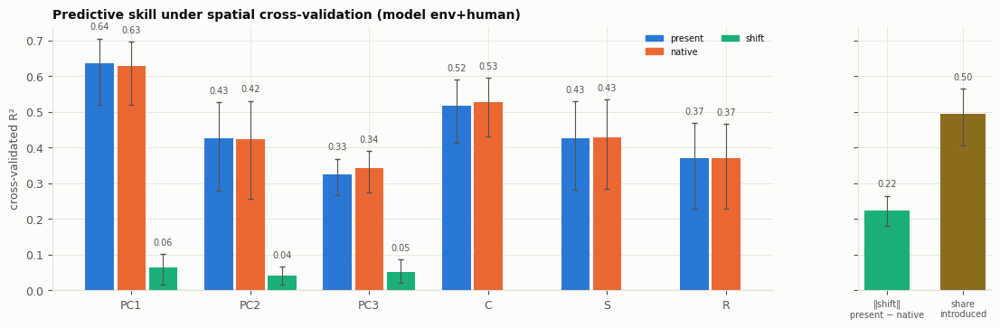

In [15]:
def r2_fast(y, p):
    return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def boot_r2(r, n_boot=1000, seed=SEED):
    """95% interval of the pooled CV R², resampling whole folds with replacement."""
    rng_b = np.random.default_rng(seed)
    folds = FOLDS[r["ok"]]
    ids = np.unique(folds)
    idx = {k: np.flatnonzero(folds == k) for k in ids}
    vals = [r2_fast(r["y"][pick], r["oof"][pick]) for pick in
            (np.concatenate([idx[k] for k in rng_b.choice(ids, len(ids))]) for _ in range(n_boot))]
    return np.quantile(vals, [0.025, 0.975])

CI = {key: boot_r2(r) for key, r in RESULTS.items()}
metrics["r2_ci_low"] = [CI[(m, t)][0] for m, t in zip(metrics["mode"], metrics["trait_pc"])]
metrics["r2_ci_high"] = [CI[(m, t)][1] for m, t in zip(metrics["mode"], metrics["trait_pc"])]
metrics.to_csv(OUT_DIR / "cv_metrics.csv", index=False)

bar_modes = [m for m in MODES if set(MODE_TARGETS[m]) & set(TARGET_COLS)]
extra = [(m, t) for m in MODES for t in MODE_TARGETS[m] if t not in TARGET_COLS]   # introduced share, Δ distance
fig, axes = plt.subplots(1, 2 if extra else 1, sharey=True, squeeze=False,
                         figsize=(max(6.5, 1.5 * len(TARGET_COLS) + 2) + 1.2 * len(extra), 3.8),
                         gridspec_kw={"width_ratios": [len(TARGET_COLS) * max(len(bar_modes), 1) * 0.6, 1.0 * len(extra)]} if extra else {})
ax = axes[0, 0]
w = 0.8 / max(len(bar_modes), 1)
x = np.arange(len(TARGET_COLS))
def bars(ax, xs, keys, width):
    for xi, (m, t) in zip(xs, keys):
        v, (lo, hi) = RESULTS[(m, t)]["r2"], CI[(m, t)]
        ax.bar(xi, v, width=width, color=MODE_COLORS[m], zorder=2)
        ax.errorbar(xi, v, yerr=[[v - lo], [hi - v]], fmt="none", ecolor=INK2, lw=0.8, capsize=2, zorder=3)
        ax.text(xi, max(hi, 0) + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color=INK2)
for i, mode in enumerate(bar_modes):
    keys = [(mode, t) for t in TARGET_COLS if t in MODE_TARGETS[mode]]      # e.g. no shift bars for C, S, R
    xs = [x[TARGET_COLS.index(t)] + (i - (len(bar_modes) - 1) / 2) * w for _, t in keys]
    bars(ax, xs, keys, w * 0.9)
ax.axhline(0, color=INK2, lw=0.8)
ax.set_xticks(x, TARGET_COLS)
ax.set_ylabel("cross-validated R²")
ax.set_title(f"Predictive skill under spatial cross-validation (model {MODEL})", loc="left")
ax.legend(handles=[mpl.patches.Patch(color=MODE_COLORS[m], label=MODE_LABELS[m]) for m in bar_modes],
          ncol=min(len(bar_modes), 2), loc="upper right", fontsize=7)
if extra:
    ax2 = axes[0, 1]
    bars(ax2, np.arange(len(extra)), extra, 0.6)
    ax2.axhline(0, color=INK2, lw=0.8)
    XL = {("shift", "length"): "‖shift‖\npresent − native", ("intro_share", "share"): "share\nintroduced",
          ("delta", "distance"): "Δ distance\nintro − native"}
    ax2.set_xticks(np.arange(len(extra)), [XL.get((m, t), f"{m}\n{t}") for m, t in extra], fontsize=7)
savefig(fig, "01_cv_r2")
plt.show()

### 5.2 Which predictors matter, and in which direction? (key figure)
**Left:** the share of total mean |SHAP| that each predictor contributes. Each column sums to 100%. This is the analogue of Mahecha et al. Fig. 4i–l.

With `GROUP_DATA_SHAP = True`, records and missingness appear as one row, "data quality". Its SHAP value is the sum of theirs for each cell, which avoids splitting credit arbitrarily between two overlapping measures. A small data-quality share and climate and soil rankings that match model 1 mean the conclusions don't depend on sampling.
**Right:** the direction of each effect, as the Spearman correlation between a predictor's value and its SHAP value. Blue means higher values of the predictor lower the trait PC; red means they raise it. Empty cells are predictors that carry less than 2% of the signal for that target, where a direction would be noise. A dashed outline marks an important (≥ 10%) but non-monotonic effect (|ρ| < 0.3): look at its dependence plot.

How much of each model's explained signal goes to data quality (log records (sampling), trait missingness):


,present|PC1,present|PC2,present|PC3,present|C,present|S,present|R,native|PC1,native|PC2,native|PC3,native|C,native|S,native|R,shift|PC1,shift|PC2,shift|PC3,shift|length,intro_share|share
data-quality share of SHAP (%),6.8,7.0,9.1,12.2,11.5,10.6,6.7,7.7,8.7,11.3,12.1,13.9,13.9,21.5,16.4,26.3,13.9


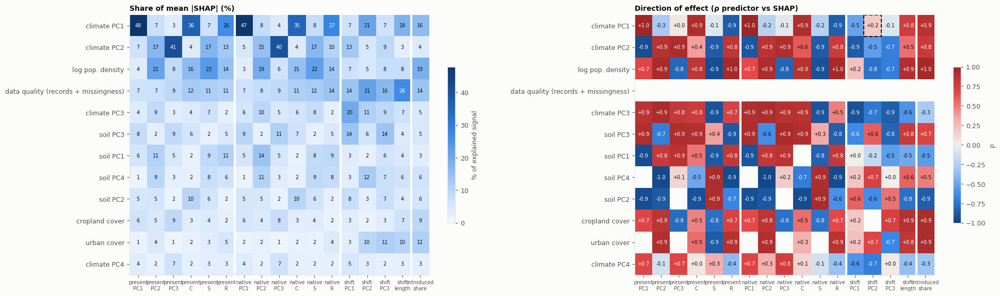

In [16]:
targets_order = [(m, pc) for m in MODES for pc in MODE_TARGETS[m]]
SHORT = {"present": "present", "native": "native", "shift": "shift", "intro_share": "introduced", "delta": "Δ"}
col_labels = [f"{SHORT[m]}\n{pc}" for m, pc in targets_order]
mode_breaks = [k for k in range(1, len(targets_order)) if targets_order[k][0] != targets_order[k - 1][0]]

SAMPLING_COLS = [c for c in ["log_records", "trait_missingness"] if c in RESULTS[targets_order[0]]["shap"]]

def grouped_shap(r):
    """SHAP table with the data-quality covariates summed into one column (valid because SHAP values add up)."""
    sd = r["shap"]
    if not (GROUP_DATA_SHAP and len(SAMPLING_COLS) > 1):
        return sd
    return sd.drop(columns=SAMPLING_COLS).assign(**{"data quality (combined)": sd[SAMPLING_COLS].sum(axis=1)})

importance = pd.DataFrame({f"{m}|{pc}": grouped_shap(RESULTS[(m, pc)]).abs().mean() for m, pc in targets_order})
share = importance / importance.sum() * 100
direction = pd.DataFrame({
    f"{m}|{pc}": {c: (spearmanr(RESULTS[(m, pc)]["X"][c], RESULTS[(m, pc)]["shap"][c]).correlation
                      if c in RESULTS[(m, pc)]["X"] else np.nan)        # no single direction for a combined group
                  for c in importance.index}
    for m, pc in targets_order}).loc[importance.index]

if SAMPLING_COLS:
    sampling_share = pd.DataFrame({f"{m}|{pc}": (RESULTS[(m, pc)]["shap"][SAMPLING_COLS].sum(axis=1).abs().mean()
                                                 / grouped_shap(RESULTS[(m, pc)]).abs().mean().sum() * 100)
                                   for m, pc in targets_order}, index=["data-quality share of SHAP (%)"]).round(1)
    print("How much of each model's explained signal goes to data quality (" + ", ".join(pretty(c) for c in SAMPLING_COLS) + "):")
    display(sampling_share)
    sampling_share.to_csv(OUT_DIR / "shap_sampling_share.csv")

row_order = share.mean(axis=1).sort_values(ascending=False).index
share, direction = share.loc[row_order], direction.loc[row_order]
MIN_SHARE = 2.0   # % — direction is only shown where a predictor carries at least this much signal
importance.loc[row_order].to_csv(OUT_DIR / "shap_mean_abs.csv")
share.to_csv(OUT_DIR / "shap_share_percent.csv")
direction.to_csv(OUT_DIR / "shap_direction_spearman.csv")

fig, axes = plt.subplots(1, 2, figsize=(max(14, 1.0 * len(col_labels) + 5), 0.38 * len(row_order) + 2),
                         gridspec_kw=dict(wspace=0.35))
for ax, data, cmap, norm, fmt, title, cbar_label in [
    (axes[0], share, SEQ, mpl.colors.Normalize(0, max(share.values.max(), 1)), "{:.0f}",
     "Share of mean |SHAP| (%)", "% of explained signal"),
    (axes[1], direction.where(share >= MIN_SHARE), DIV, TwoSlopeNorm(0, -1, 1), "{:+.1f}",
     "Direction of effect (ρ predictor vs SHAP)", "ρ"),
]:
    ax.grid(False)
    im = ax.imshow(data.values, cmap=cmap, norm=norm, aspect="auto")
    ax.set_xticks(range(len(col_labels)), col_labels, fontsize=7)
    ax.set_yticks(range(len(row_order)), [pretty(c) for c in row_order])
    for b in mode_breaks:
        ax.axvline(b - 0.5, color=SURFACE, lw=3)
    for (i, j), v in np.ndenumerate(data.values):
        if np.isfinite(v):
            rgba = cmap(norm(v))
            lum = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=7,
                    color="white" if lum < 0.5 else INK)
    ax.set_title(title, loc="left")
    fig.colorbar(im, ax=ax, shrink=0.6, label=cbar_label)
# dashed outline = important (≥ 10% of signal) but non-monotonic effect (|ρ| < 0.3)
for i, j in zip(*np.where(((share >= 10) & (direction.abs() < 0.3)).to_numpy())):
    axes[1].add_patch(mpl.patches.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=1.4, ls="--", zorder=5))
savefig(fig, "02_shap_heatmaps")
plt.show()

### 5.2b Predictor blocks: environment, human pressure, data quality
SHAP values add up, so each block's contribution in a cell is the sum of its predictors' SHAP values. The bars show each block's share of the explained signal per target. Reading blocks rather than single variables is more robust when predictors within a block are correlated (population density, cropland and urban cover are). In model "env", only climate and soil appear.

,present|PC1,present|PC2,present|PC3,present|C,present|S,present|R,native|PC1,native|PC2,native|PC3,native|C,native|S,native|R,shift|PC1,shift|PC2,shift|PC3,shift|length,intro_share|share
climate,64.0,31.0,53.0,46.0,30.0,40.0,63.0,31.0,54.0,47.0,31.0,38.0,39.0,38.0,24.0,27.0,25.0
soil,16.0,23.0,15.0,16.0,20.0,20.0,18.0,27.0,18.0,17.0,21.0,20.0,26.0,19.0,29.0,14.0,14.0
human pressure,12.0,36.0,20.0,23.0,36.0,26.0,11.0,32.0,17.0,22.0,33.0,23.0,15.0,13.0,23.0,27.0,43.0
data quality,8.0,9.0,11.0,15.0,14.0,14.0,8.0,10.0,11.0,14.0,15.0,18.0,20.0,30.0,23.0,32.0,18.0


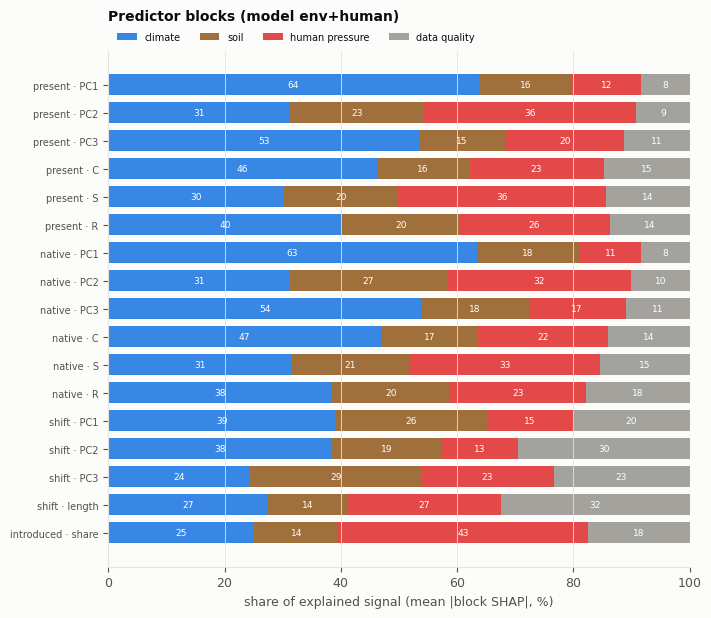

In [17]:
BLOCKS = {
    "climate": [c for c in FEATURES.columns if c.startswith("clim_")],
    "soil": [c for c in FEATURES.columns if c.startswith("soil_")],
    "human pressure": [c for c in ["log_pop_density"] + lu_cols if c in FEATURES.columns],
    "life history": [LH_COL] if LH_COL else [],
    "data quality": ["log_records", "trait_missingness"],
}
BLOCK_COLORS = {"climate": "#3987e5", "soil": "#a0703c", "human pressure": "#e34948",
                "life history": "#1baf7a", "data quality": "#a3a29d"}

def block_shares(r):
    sd = r["shap"]
    tot = pd.Series({b: sd[[c for c in cols if c in sd]].sum(axis=1).abs().mean()
                     for b, cols in BLOCKS.items() if any(c in sd for c in cols)})
    return tot / tot.sum() * 100

block_tab = pd.DataFrame({f"{m}|{pc}": block_shares(RESULTS[(m, pc)]) for m, pc in targets_order}).fillna(0)
block_tab.round(1).to_csv(OUT_DIR / "shap_block_shares.csv")
display(block_tab.round(0))

fig, ax = plt.subplots(figsize=(7.5, 0.3 * len(targets_order) + 1.6))
ypos = np.arange(len(targets_order))[::-1]
left = np.zeros(len(targets_order))
for b in block_tab.index:
    v = block_tab.loc[b].to_numpy()
    ax.barh(ypos, v, left=left, color=BLOCK_COLORS[b], height=0.75, label=b)
    for yy, l0, vv in zip(ypos, left, v):
        if vv >= 8:
            ax.text(l0 + vv / 2, yy, f"{vv:.0f}", ha="center", va="center", fontsize=6.5, color="white")
    left += v
ax.set_yticks(ypos, [l.replace("\n", " · ") for l in col_labels], fontsize=7)
ax.set_xlim(0, 100); ax.set_xlabel("share of explained signal (mean |block SHAP|, %)")
ax.grid(axis="y", visible=False)
ax.legend(ncol=len(block_tab.index), loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=7)
ax.set_title(f"Predictor blocks (model {MODEL})", loc="left", pad=22)
savefig(fig, "02b_shap_block_shares")
plt.show()

### 5.3 SHAP summary per target
Each dot is one H3 cell. Its position shows how much a predictor pushes that cell's trait PC up or down. Its colour shows the predictor's value in that cell, from low (blue) to high (red), as percentile ranks.

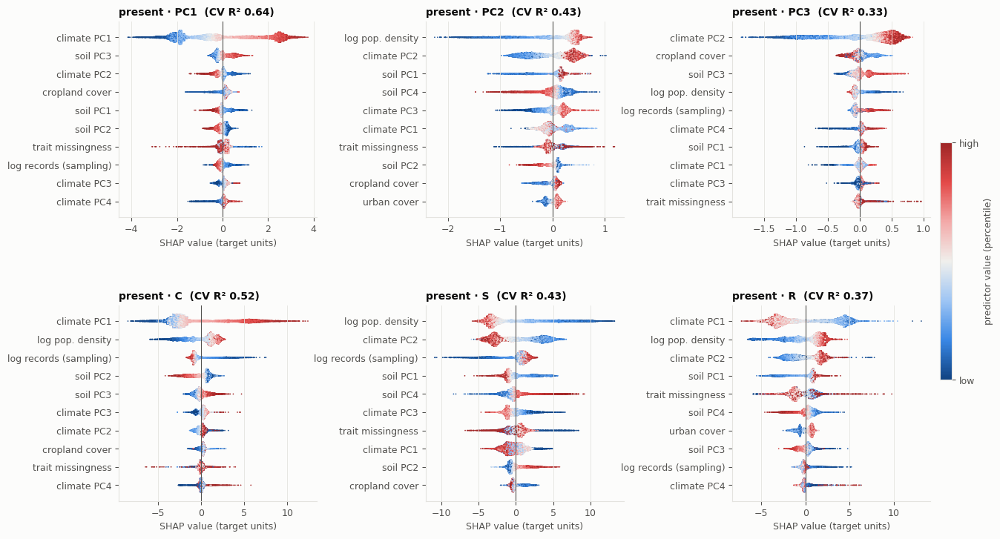

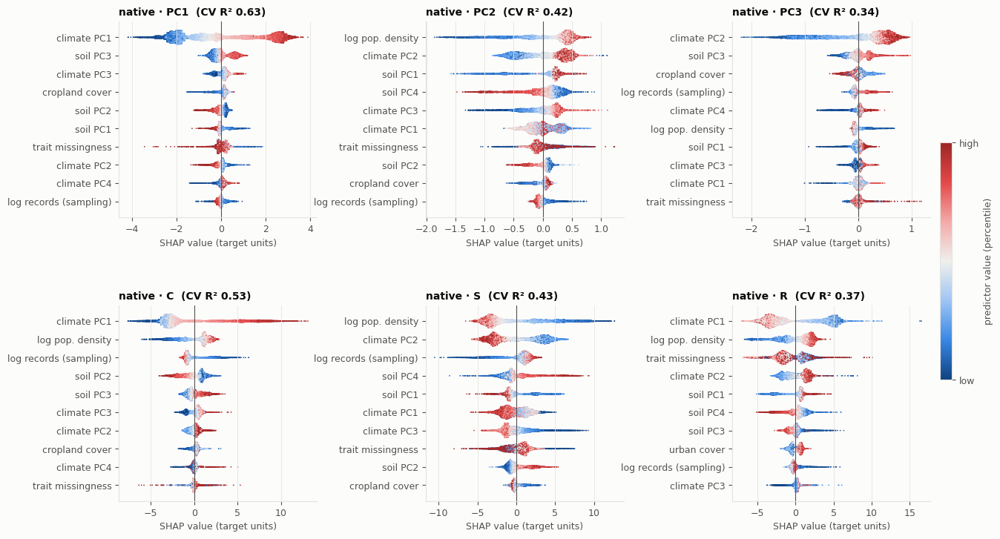

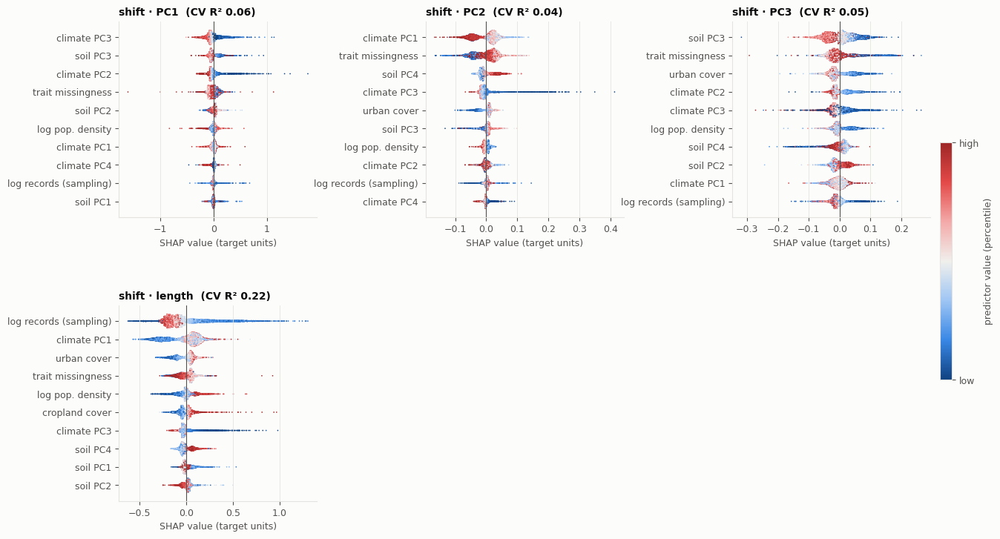

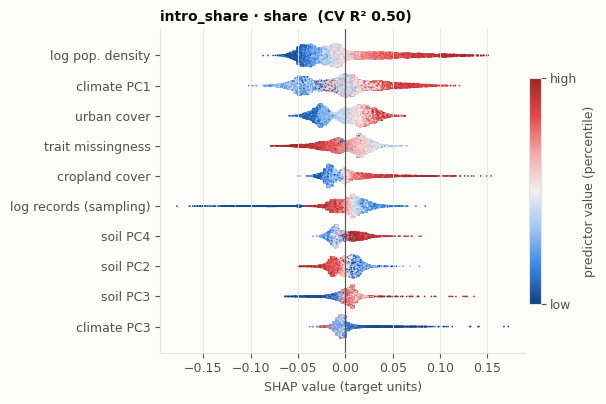

In [18]:
def beeswarm(ax, shap_df, X, max_display=10, title=""):
    order = shap_df.abs().mean().sort_values(ascending=False).index[:max_display][::-1]
    rng_b = np.random.default_rng(0)
    for row, feat in enumerate(order):
        s = shap_df[feat].to_numpy()
        v = X[feat].rank(pct=True).to_numpy()
        # jitter scaled by local density so dense regions spread out
        hist, edges = np.histogram(s, bins=60)
        dens = hist[np.clip(np.digitize(s, edges) - 1, 0, len(hist) - 1)] / hist.max()
        yj = row + rng_b.uniform(-0.38, 0.38, len(s)) * dens
        ax.scatter(s, yj, c=v, cmap=DIV, vmin=0, vmax=1, s=1.5, linewidths=0, rasterized=True)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_yticks(range(len(order)), [pretty(f) for f in order])
    ax.set_xlabel("SHAP value (target units)")
    ax.set_title(title, loc="left")
    ax.grid(axis="y", visible=False)

for mode in MODES:
    tg = MODE_TARGETS[mode]
    NCOL = min(3, len(tg))
    NROW = int(np.ceil(len(tg) / NCOL))
    fig, axes = plt.subplots(NROW, NCOL, figsize=(5.6 * NCOL, 4.2 * NROW), squeeze=False,
                             gridspec_kw=dict(wspace=0.55, hspace=0.45))
    for ax, pc in zip(axes.flat, tg):
        r = RESULTS[(mode, pc)]
        beeswarm(ax, r["shap"], r["X"], title=f"{mode} · {pc}  (CV R² {r['r2']:.2f})")
    for ax in list(axes.flat)[len(tg):]:
        ax.set_visible(False)
    sm = mpl.cm.ScalarMappable(cmap=DIV, norm=mpl.colors.Normalize(0, 1))
    cb = fig.colorbar(sm, ax=axes.ravel().tolist(), shrink=0.7 / NROW ** 0.5, pad=0.01)
    cb.set_ticks([0, 1], labels=["low", "high"]); cb.set_label("predictor value (percentile)")
    savefig(fig, f"03_shap_beeswarm_{mode}")
    plt.show()

### 5.4 Dependence plots: response curves of the three strongest predictors
Each panel plots predictor value against SHAP value. The dark line is the binned median, which approximates the partial effect of that predictor.

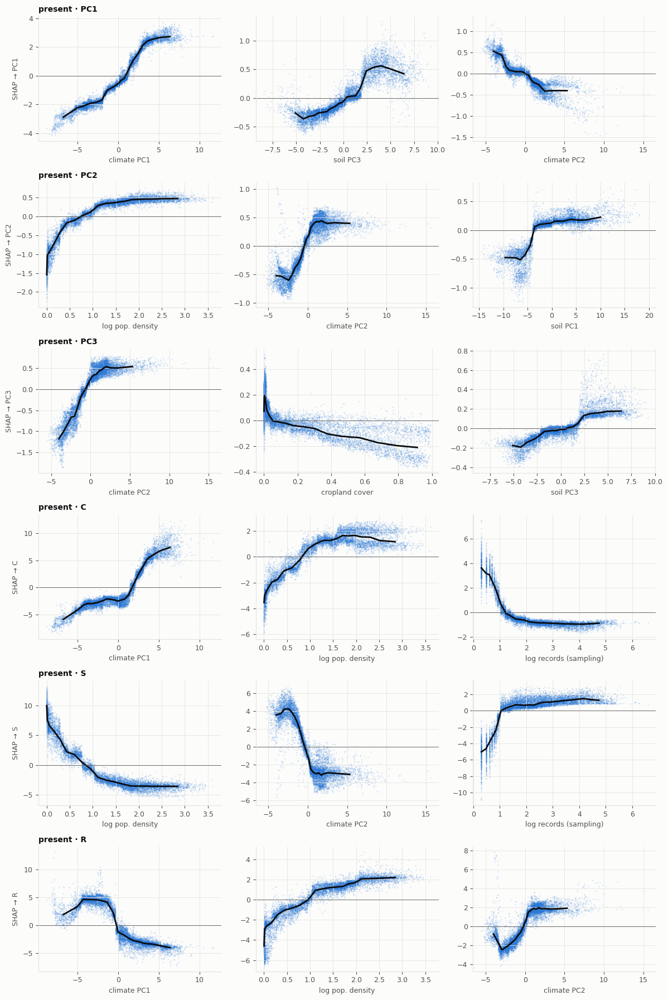

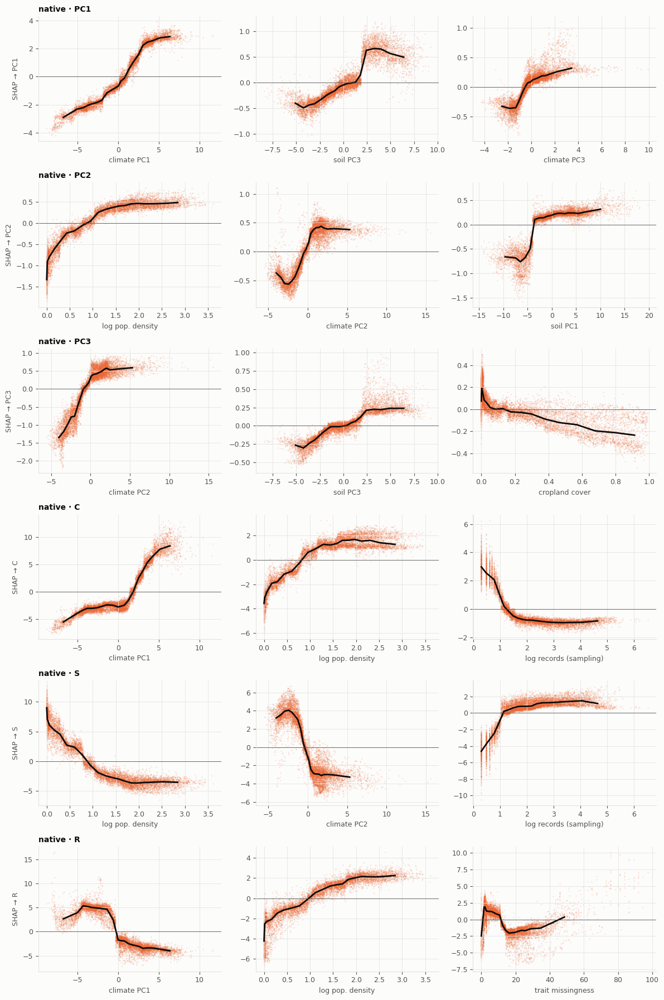

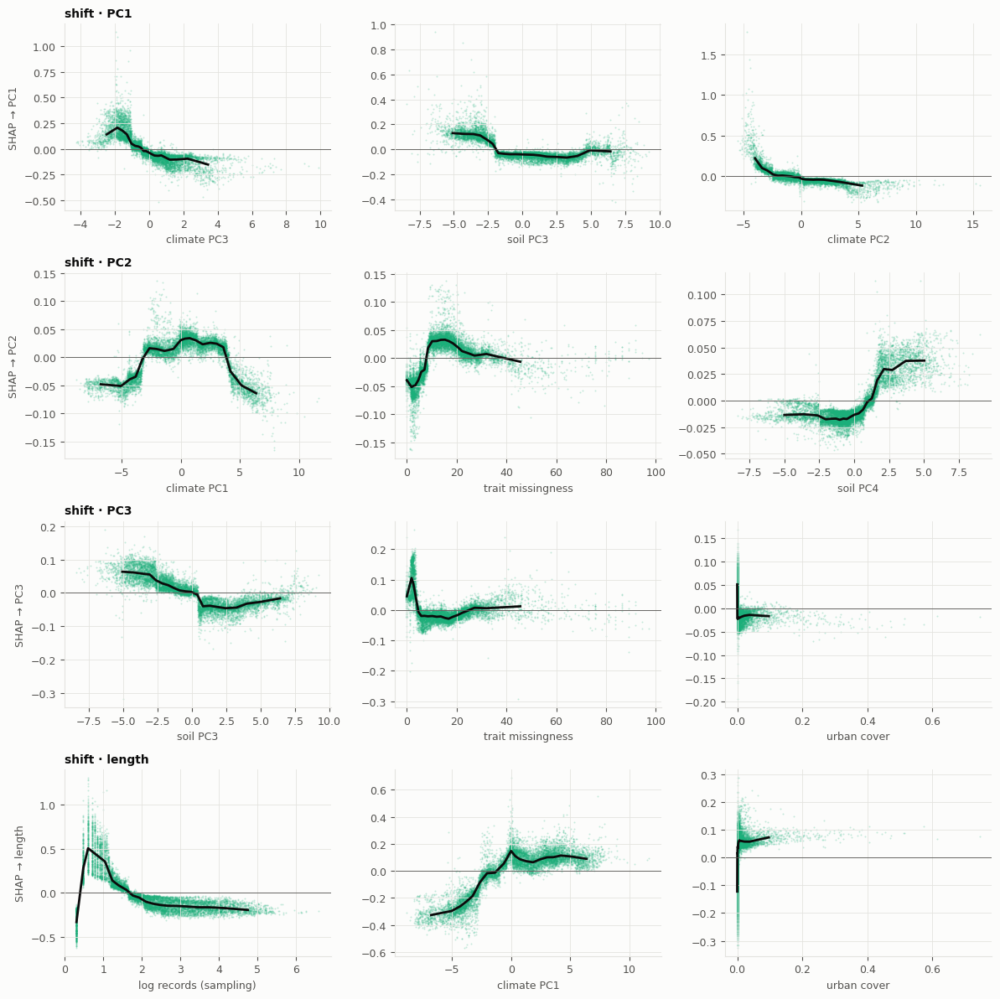

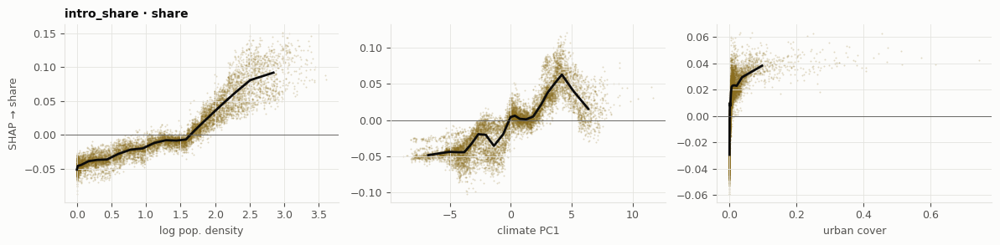

In [19]:
def binned_median(x, y, bins=20):
    q = np.unique(np.quantile(x, np.linspace(0, 1, bins + 1)))
    idx = np.clip(np.digitize(x, q) - 1, 0, len(q) - 2)
    xm = np.array([np.median(x[idx == b]) for b in range(len(q) - 1) if (idx == b).any()])
    ym = np.array([np.median(y[idx == b]) for b in range(len(q) - 1) if (idx == b).any()])
    return xm, ym

TOP_K = 3
for mode in MODES:
    tg = MODE_TARGETS[mode]
    fig, axes = plt.subplots(len(tg), TOP_K, figsize=(4 * TOP_K, 3 * len(tg)), squeeze=False)
    for i, pc in enumerate(tg):
        sd = RESULTS[(mode, pc)]["shap"]
        for j, feat in enumerate(sd.abs().mean().sort_values(ascending=False).index[:TOP_K]):
            ax = axes[i, j]
            x, s = RESULTS[(mode, pc)]["X"][feat].to_numpy(), sd[feat].to_numpy()
            ax.scatter(x, s, s=2, color=MODE_COLORS[mode], alpha=0.25, linewidths=0, rasterized=True)
            ax.plot(*binned_median(x, s), color=INK, lw=2)
            ax.axhline(0, color=INK2, lw=0.6)
            ax.set_xlabel(pretty(feat)); ax.set_ylabel(f"SHAP → {pc}" if j == 0 else "")
            ax.set_title(f"{mode} · {pc}" if j == 0 else "", loc="left")
    fig.tight_layout()
    savefig(fig, f"04_shap_dependence_{mode}")
    plt.show()

### 5.5 Maps: observed, predicted (out-of-fold) and residuals
Look for spatial structure in the residuals. It shows where the predictors miss something, such as biogeographic history, sampling, or introduction pressure.

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

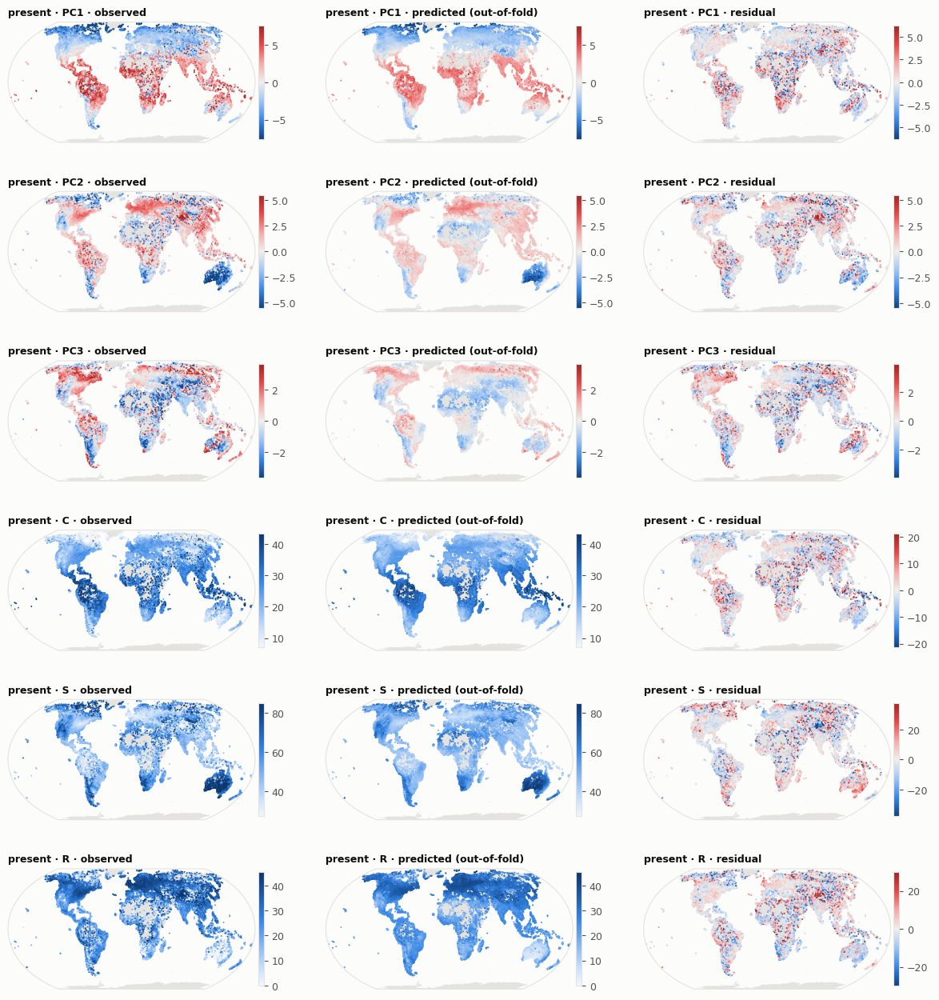

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


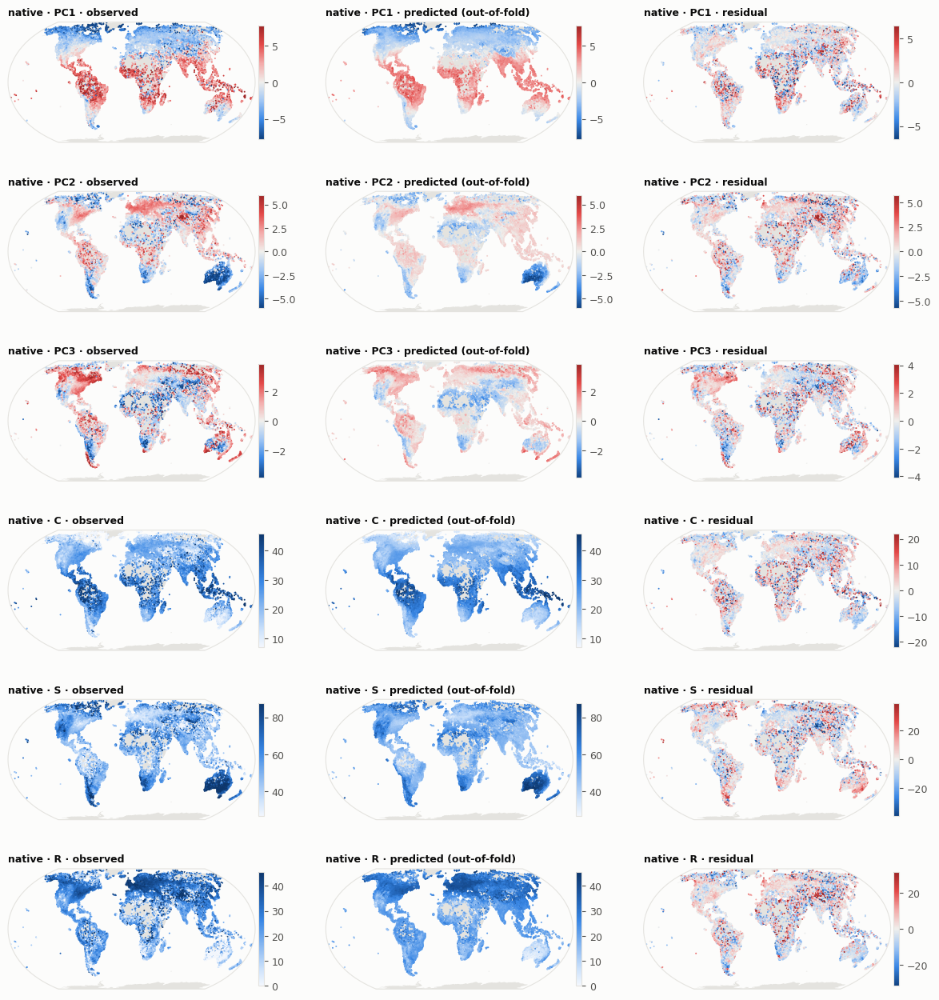

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


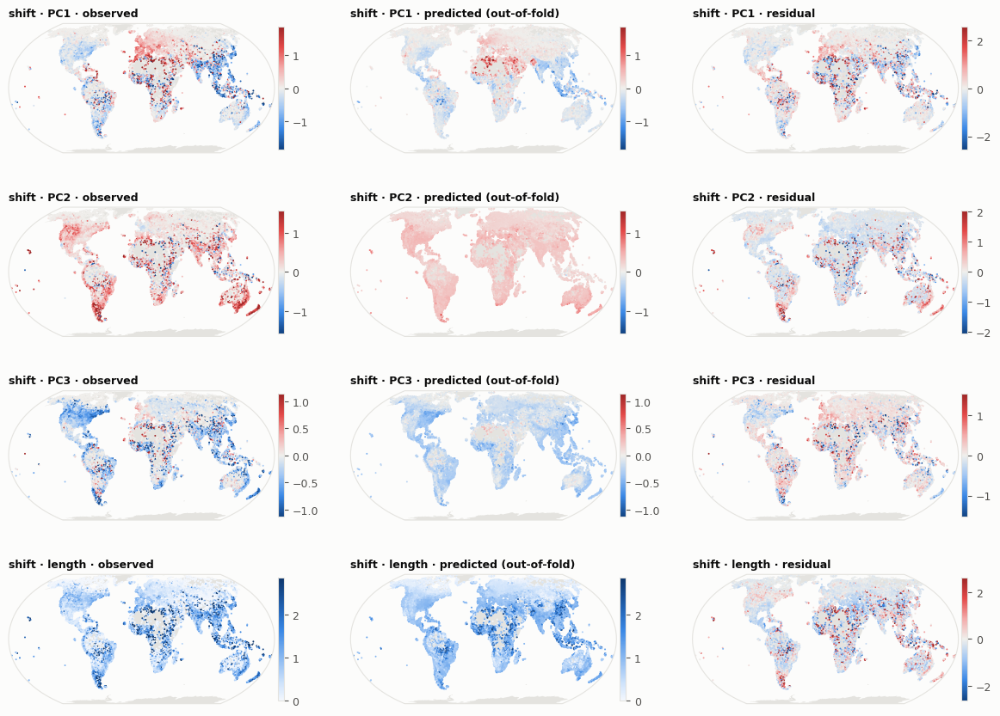

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


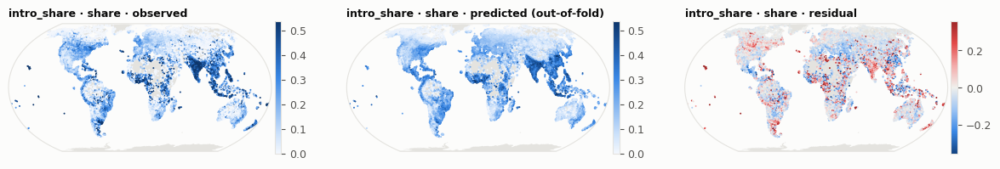

In [20]:
def sym_limits(*arrays, q=0.98):
    v = np.nanquantile(np.abs(np.concatenate(arrays)), q)
    return -v, v

for mode in MODES:
    tg = MODE_TARGETS[mode]
    fig = plt.figure(figsize=(15, 2.7 * len(tg)))
    fig.subplots_adjust(hspace=0.12, wspace=0.08)
    for i, pc in enumerate(tg):
        r = RESULTS[(mode, pc)]
        resid = r["y"] - r["oof"]
        # trait PCs, shifts and Δ are centred on 0; CSR scores, the introduced share and Δ distance are not
        centred = (mode in ("shift", "delta") and pc not in ("distance", "length")) or (mode in ("present", "native") and pc not in CSR)
        lo, hi = sym_limits(r["y"], r["oof"]) if centred else tuple(np.nanquantile(np.r_[r["y"], r["oof"]], [.02, .98]))
        rlo, rhi = sym_limits(resid)
        for j, (vals, title, lim) in enumerate([(r["y"], "observed", (lo, hi)),
                                               (r["oof"], "predicted (out-of-fold)", (lo, hi)),
                                               (resid, "residual", (rlo, rhi))]):
            ax, tf = map_axes(fig, (len(tg), 3, i * 3 + j + 1))
            plain = (j < 2) and not centred
            sc = ax.scatter(LON[r["ok"]], LAT[r["ok"]], c=vals, cmap=SEQ if plain else DIV,
                            norm=mpl.colors.Normalize(*lim) if plain else TwoSlopeNorm(0, lim[0], lim[1]),
                            s=2, linewidths=0, rasterized=True, **tf)
            ax.set_title(f"{mode} · {pc} · {title}", loc="left", fontsize=9)
            fig.colorbar(sc, ax=ax, shrink=0.75, pad=0.01)
    savefig(fig, f"05_maps_{mode}")
    plt.show()

### 5.6 Residual diagnostics: do sampling effort and trait missingness affect accuracy?
These plots show the absolute out-of-fold residual against the number of records per cell, population density and the cell's trait missingness (each for the modelled group). Lines are binned medians and bands are interquartile ranges. A falling curve means poorly sampled cells are predicted less well. This is a diagnostic only; nothing here feeds back into the model.

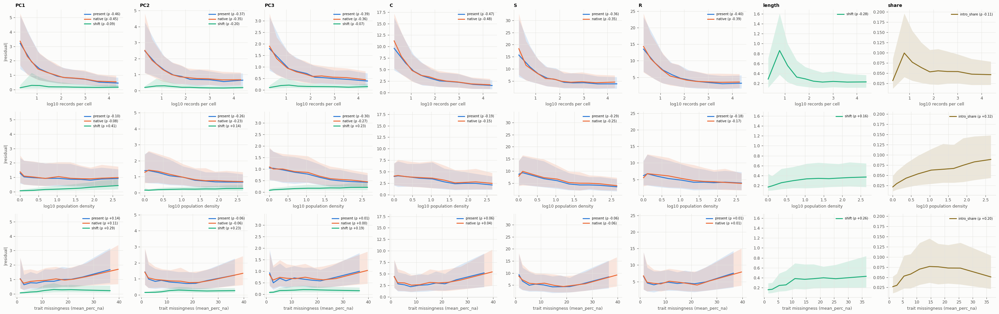

In [21]:
# each entry: label -> function(mode) giving the x values for that mode's cells
diag_vars = {"log10 records per cell":
             lambda mode: np.log10(cell_info.loc[CELLS, f"n_records_{group_of(mode)}"].to_numpy() + 1)}
if "log_pop_density" in FEATURES:
    diag_vars["log10 population density"] = lambda mode: FEATURES["log_pop_density"].to_numpy()
if NA_COL:
    diag_vars["trait missingness (mean_perc_na)"] = lambda mode: cell_info.loc[CELLS, f"missing_{group_of(mode)}"].to_numpy()

ALL_T = list(dict.fromkeys(t for m in MODES for t in MODE_TARGETS[m]))
fig, axes = plt.subplots(len(diag_vars), len(ALL_T), figsize=(3.8 * len(ALL_T), 3.2 * len(diag_vars)),
                         squeeze=False, sharey="col")
for i, (xlabel, xfun) in enumerate(diag_vars.items()):
    for j, pc in enumerate(ALL_T):
        ax = axes[i, j]
        for mode in MODES:
            if (mode, pc) not in RESULTS:
                continue
            r = RESULTS[(mode, pc)]
            xv = xfun(mode)[r["ok"]]
            ar = np.abs(r["y"] - r["oof"])
            q = np.unique(np.quantile(xv, np.linspace(0, 1, 11)))
            idx = np.clip(np.digitize(xv, q) - 1, 0, len(q) - 2)
            bins = [b for b in range(len(q) - 1) if (idx == b).any()]
            bx = [np.median(xv[idx == b]) for b in bins]
            bq = np.array([np.quantile(ar[idx == b], [.25, .5, .75]) for b in bins])
            rho = spearmanr(xv, ar).correlation
            ax.fill_between(bx, bq[:, 0], bq[:, 2], color=MODE_COLORS[mode], alpha=0.15, linewidth=0)
            ax.plot(bx, bq[:, 1], color=MODE_COLORS[mode], lw=2, label=f"{mode} (ρ {rho:+.2f})")
        ax.set_xlabel(xlabel); ax.set_ylabel("|residual|" if j == 0 else "")
        ax.set_title(pc if i == 0 else "", loc="left")
        ax.legend(fontsize=7)
fig.tight_layout()
savefig(fig, "06_residual_diagnostics")
plt.show()

## 6 · Save everything

In [22]:
pred_long = pd.concat([
    pd.DataFrame({"h3_index": CELLS[r["ok"]], "mode": m, "trait_pc": pc, "observed": r["y"], "predicted_oof": r["oof"],
                  "residual": r["y"] - r["oof"], "fold": FOLDS[r["ok"]], "lat": LAT[r["ok"]], "lon": LON[r["ok"]]})
    for (m, pc), r in RESULTS.items()])
shap_long = pd.concat([
    r["shap"].assign(mode=m, trait_pc=pc, base_value=r["base"]).reset_index()
    for (m, pc), r in RESULTS.items()])

def save_table(df, stem):
    try:
        df.to_parquet(OUT_DIR / f"{stem}.parquet", index=False); return f"{stem}.parquet"
    except ImportError:
        df.to_csv(OUT_DIR / f"{stem}.csv.gz", index=False); return f"{stem}.csv.gz"

saved = [save_table(pred_long, "predictions_oof"), save_table(shap_long, "shap_values"),
         save_table(FEATURES.reset_index(), "model_features")]
clim_load.to_csv(OUT_DIR / "climate_pca_loadings.csv")
soil_load.to_csv(OUT_DIR / "soil_pca_loadings.csv")
for (m, pc), r in RESULTS.items():
    r["model"].save_model(OUT_DIR / f"xgb_{m}_{pc}.json")

print("written to", OUT_DIR.resolve())
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(OUT_DIR))

written to /net/home/swolf/Func_Neo_Phytes/Results/trait_env/env+human
   climate_pca_loadings.csv
   cv_metrics.csv
   model_comparison_vs_env.csv
   model_features.csv.gz
   predictions_oof.csv.gz
   shap_block_shares.csv
   shap_direction_spearman.csv
   shap_mean_abs.csv
   shap_sampling_share.csv
   shap_share_percent.csv
   shap_values.csv.gz
   soil_pca_loadings.csv
   spatial_folds.csv
   xgb_delta_distance.json
   xgb_intro_share_share.json
   xgb_native_C.json
   xgb_native_PC1.json
   xgb_native_PC2.json
   xgb_native_PC3.json
   xgb_native_R.json
   xgb_native_S.json
   xgb_present_C.json
   xgb_present_PC1.json
   xgb_present_PC2.json
   xgb_present_PC3.json
   xgb_present_R.json
   xgb_present_S.json
   xgb_shift_PC1.json
   xgb_shift_PC2.json
   xgb_shift_PC3.json
   xgb_shift_length.json


## 7 · Methods paragraph (draft, filled from this run)

In [23]:
csr_txt = (" (C, S and R: community-mean CSR strategy scores, which sum to 100%)" if CSR else "")
human = ([f"log10-transformed population density ({POP_SOURCE})"] if USE_POP else []) + \
        ([f"{', '.join(PRETTY.get(c, c) for c in lu_cols)} ({LANDCOVER_SOURCE})"] if USE_LANDCOVER else [])
data_q = (["the number of occurrence records per cell (log10)"] if USE_RECORDS else []) + \
         (["the cell's mean trait missingness"] if USE_MISSINGNESS else [])
extra_txt = ""
if human:
    extra_txt += "; human pressure: " + " and ".join(human)
if data_q:
    extra_txt += "; data quality: " + " and ".join(data_q)
if LH_COL:
    extra_txt += (f"; and the percentage of {LIFEHISTORY_COL.replace('_percentage', '')} species per cell "
                  f"(derived from the same occurrence records)")
if CLIMATE_SET == "bio_summaries":
    clim_txt = ("WorldClim 2.1 variables (the 19 bioclimatic variables plus the annual mean and seasonal coefficient of "
                "variation of solar radiation, wind speed and water vapour pressure"
                + ("; rain–radiation synchrony and the number of dry months" if CLIMATE_EXTRAS else "")
                + ("; the Global Aridity Index v3 (Zomer et al. 2022)" if "wc_aridity_index" in wc_cols else "")
                + "; monthly layers were not used directly because calendar months correspond to opposite seasons "
                  "in the two hemispheres)")
else:
    clim_txt = "WorldClim 2.1 variables (19 bioclimatic variables and 12 monthly layers of 7 variables)"
mode_txt = {"present": "present-day (all species)", "native": "native-only",
            "shift": (f"the shift (present − native) of {', '.join(SHIFT_COLS)}" if SHIFT_PER_PC else "")
                     + (" and " if SHIFT_PER_PC and SHIFT_LENGTH else "")
                     + (f"the length of the shift vector (‖present − native‖ across {', '.join(SHIFT_COLS)})" if SHIFT_LENGTH else ""),
            "intro_share": f"the share of introduced {unit} (p)",
            "delta": f"the trait-space distance between introduced and native species (Δ = ‖shift‖ / p across {', '.join(SHIFT_COLS)}; "
                     f"cells with ≥ {DELTA_MIN_INTRO} introduced species" + ("; also per PC" if DELTA_PER_PC else "") + ")"}
if "delta" in MODES:
    decomp_txt = (" Because the shift vector equals p × Δ (and hence ‖shift‖ = p × ‖Δ‖), it was additionally decomposed into how many "
                  "introduced species a cell holds (p) and how far their mean traits lie from those of the natives (Δ), and both were "
                  "modelled separately.")
elif "intro_share" in MODES:
    decomp_txt = (" The share of introduced species, which scales the shift (‖shift‖ = p × Δ, with Δ the trait-space distance between "
                  "introduced and native species), was modelled as a separate response.")
else:
    decomp_txt = ""
print(f"""We related trait composition to the environment with gradient-boosted trees (XGBoost {xgb.__version__}).
Predictors were the first {len(clim_var)} principal components of {len(wc_cols)} standardised {clim_txt}
({clim_var.sum():.0%} of variance) and the first {len(soil_var)} principal components of {len(sg_cols)} standardised SoilGrids 2.0
variables ({soil_var.sum():.0%} of variance){extra_txt}. Separate models were fitted for the present-day and native-only
values of {', '.join(TARGET_COLS)}{csr_txt}, and for {'; '.join(mode_txt[m] for m in MODES if m not in ('present', 'native'))},
across {len(CELLS)} H3 resolution-3 cells.{decomp_txt}
Following Mahecha et al. (2021), spatial cross-validation folds were defined by affinity propagation on an
asymmetric similarity matrix whose lower triangle contained similarities in the space of the four leading trait PCs
and whose upper triangle contained geographic proximity, yielding {N_FOLDS} folds (after merging clusters
< {MIN_FOLD_SIZE} cells). Each fold was withheld once; the number of trees was set by early stopping on a
grouped inner validation split. Predictor contributions were quantified with exact TreeSHAP values from a model
refitted on all cells. Uncertainty in cross-validated R² was estimated by resampling folds with replacement (1,000 times).""")

We related trait composition to the environment with gradient-boosted trees (XGBoost 2.1.4).
Predictors were the first 4 principal components of 26 standardised WorldClim 2.1 variables (the 19 bioclimatic variables plus the annual mean and seasonal coefficient of variation of solar radiation, wind speed and water vapour pressure; the Global Aridity Index v3 (Zomer et al. 2022); monthly layers were not used directly because calendar months correspond to opposite seasons in the two hemispheres)
(84% of variance) and the first 4 principal components of 78 standardised SoilGrids 2.0
variables (76% of variance); human pressure: log10-transformed population density (GPW v4 2020) and urban cover, cropland cover (per-cell land-cover fractions (urban, cropland, natural vegetation, barren, water)); data quality: the number of occurrence records per cell (log10) and the cell's mean trait missingness. Separate models were fitted for the present-day and native-only
values of PC1, PC2, PC3, C, S, R 

## 8 · Model comparison: what do human pressure and data quality add?
Runs when `COMPARE_WITH` points to another model's results folder (by default model "env", for a run of model "env+human"). For every mode and target, both models' out-of-fold predictions are compared on the cells both have, and the bars show the gain in R² (this model − the other). The 95% interval comes from resampling whole folds with replacement, using the same resampled folds for both models (a paired comparison). It is only valid if both runs used the same folds, which `REUSE_FOLDS` takes care of.

An interval that excludes 0 means the added predictors improve predictions in new regions. For present and native, expect a small gain; for the introduced share, human pressure is the main hypothesis.

,mode,trait_pc,n_cells,r2_other,r2_this,delta_r2,ci_low,ci_high
0,present,PC1,9484,0.618,0.635,0.017,0.006,0.029
1,present,PC2,9484,0.363,0.427,0.063,0.034,0.101
2,present,PC3,9484,0.286,0.326,0.040,0.016,0.064
3,present,C,9484,0.480,0.518,0.038,0.022,0.058
4,present,S,9484,0.347,0.425,0.079,0.051,0.115
5,present,R,9484,0.301,0.371,0.070,0.047,0.099
6,native,PC1,9484,0.609,0.629,0.020,0.012,0.029
7,native,PC2,9484,0.350,0.423,0.073,0.045,0.110
8,native,PC3,9484,0.295,0.342,0.046,0.027,0.069
9,native,C,9484,0.487,0.527,0.040,0.026,0.055


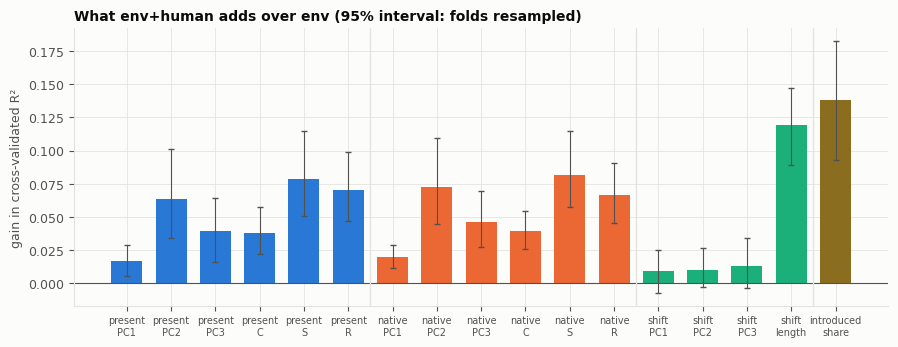

In [24]:
def load_table(folder, stem):
    for ext, reader in [(".parquet", pd.read_parquet), (".csv.gz", pd.read_csv)]:
        f = Path(folder).expanduser() / f"{stem}{ext}"
        if f.exists():
            return reader(f)
    raise FileNotFoundError(f"no {stem}.parquet or {stem}.csv.gz in {folder}")

if COMPARE_WITH is None or not Path(COMPARE_WITH).expanduser().exists():
    print("COMPARE_WITH is not set or not found: no model comparison in this run.")
else:
    other_name = Path(COMPARE_WITH).name
    other = load_table(COMPARE_WITH, "predictions_oof")
    other["h3_index"] = other["h3_index"].astype(str)
    key = ["h3_index", "mode", "trait_pc"]
    both = pred_long.assign(h3_index=pred_long["h3_index"].astype(str)).merge(
        other[key + ["predicted_oof"]], on=key, suffixes=("", "_other"))
    rng_c = np.random.default_rng(SEED)
    rows = []
    for (m, t), d in both.groupby(["mode", "trait_pc"], sort=False):
        y, a, b = d["observed"].to_numpy(), d["predicted_oof_other"].to_numpy(), d["predicted_oof"].to_numpy()
        f = d["fold"].to_numpy()
        ids = np.unique(f)
        idx = {k: np.flatnonzero(f == k) for k in ids}
        diffs = []
        for _ in range(1000):
            pick = np.concatenate([idx[k] for k in rng_c.choice(ids, len(ids))])
            diffs.append(r2_fast(y[pick], b[pick]) - r2_fast(y[pick], a[pick]))
        rows.append(dict(mode=m, trait_pc=t, n_cells=len(d), r2_other=r2_fast(y, a), r2_this=r2_fast(y, b),
                         delta_r2=r2_fast(y, b) - r2_fast(y, a),
                         ci_low=np.quantile(diffs, .025), ci_high=np.quantile(diffs, .975)))
    comp = pd.DataFrame(rows)
    comp.to_csv(OUT_DIR / f"model_comparison_vs_{other_name}.csv", index=False)
    display(comp.round(3))

    fig, ax = plt.subplots(figsize=(max(6, 0.5 * len(comp) + 2), 3.6))
    xs = np.arange(len(comp))
    ax.bar(xs, comp["delta_r2"], color=[MODE_COLORS[m] for m in comp["mode"]], width=0.7, zorder=2)
    ax.errorbar(xs, comp["delta_r2"], yerr=[comp["delta_r2"] - comp["ci_low"], comp["ci_high"] - comp["delta_r2"]],
                fmt="none", ecolor=INK2, lw=0.8, capsize=2, zorder=3)
    ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(xs, [f"{SHORT[m]}\n{t}" for m, t in zip(comp["mode"], comp["trait_pc"])], fontsize=7)
    for b in [k for k in range(1, len(comp)) if comp["mode"].iloc[k] != comp["mode"].iloc[k - 1]]:
        ax.axvline(b - 0.5, color=GRID, lw=1)
    ax.set_ylabel("gain in cross-validated R²")
    ax.set_title(f"What {MODEL} adds over {other_name} (95% interval: folds resampled)", loc="left")
    savefig(fig, f"10_model_comparison_vs_{other_name}")
    plt.show()

## Where did which driver influence which axis of trait variation?

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:
/net/home/swolf/.conda/envs/

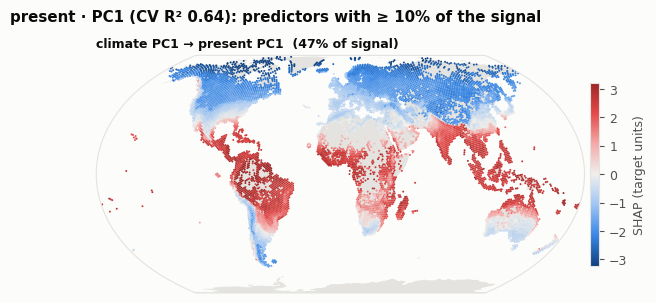

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


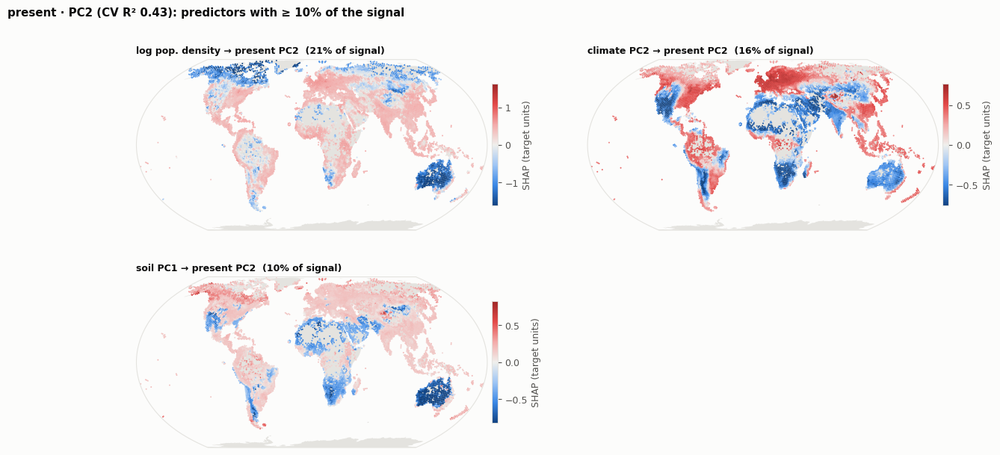

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


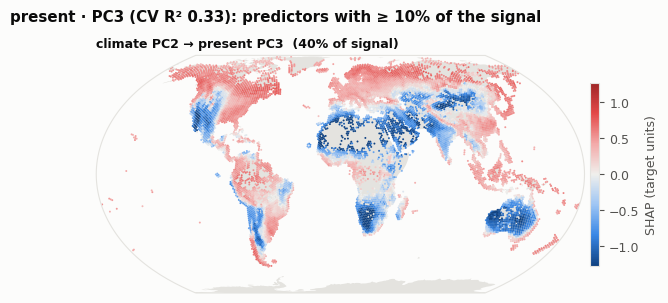

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


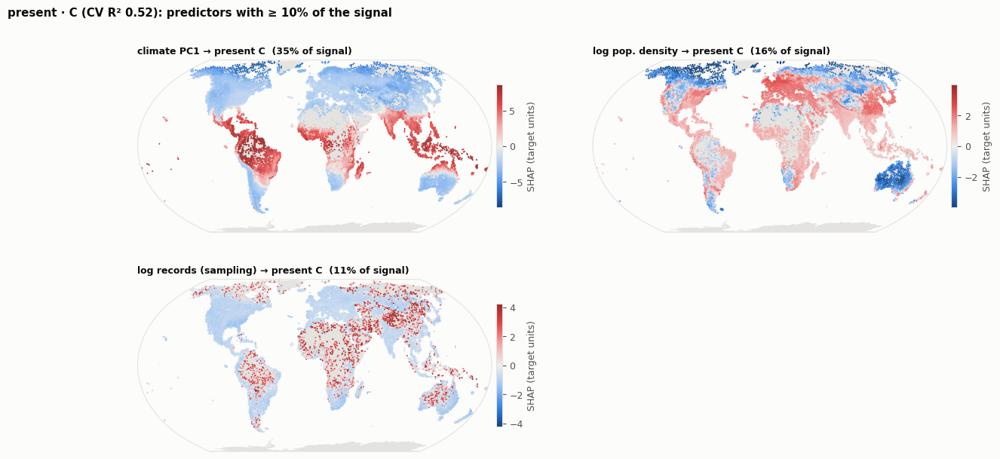

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


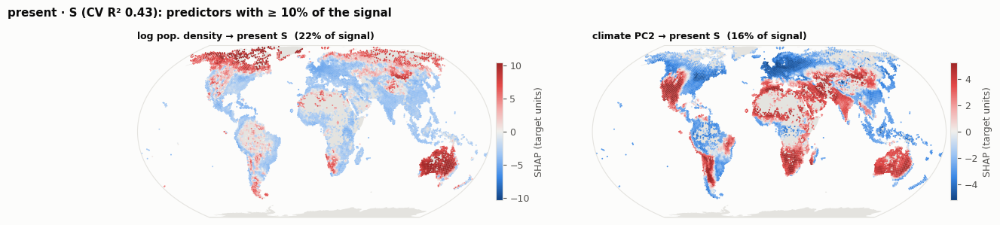

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


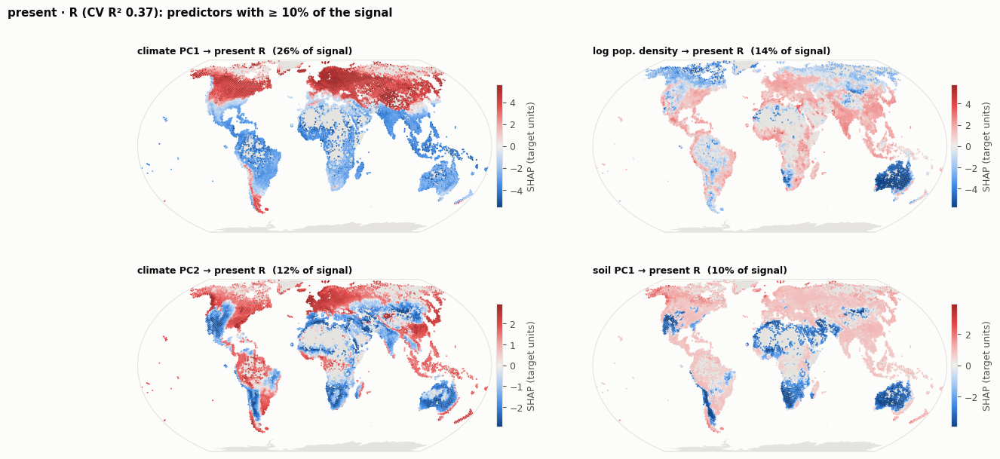

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


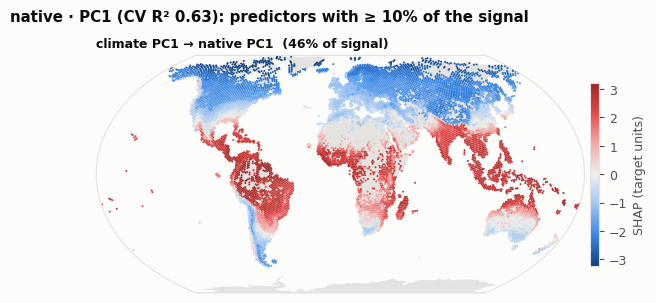

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


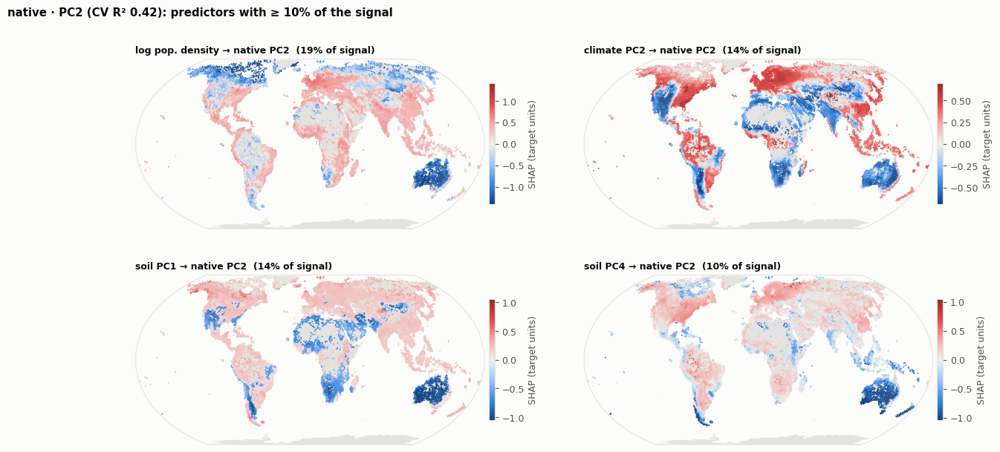

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


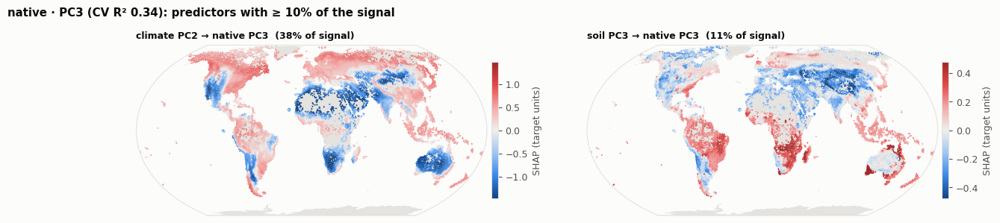

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


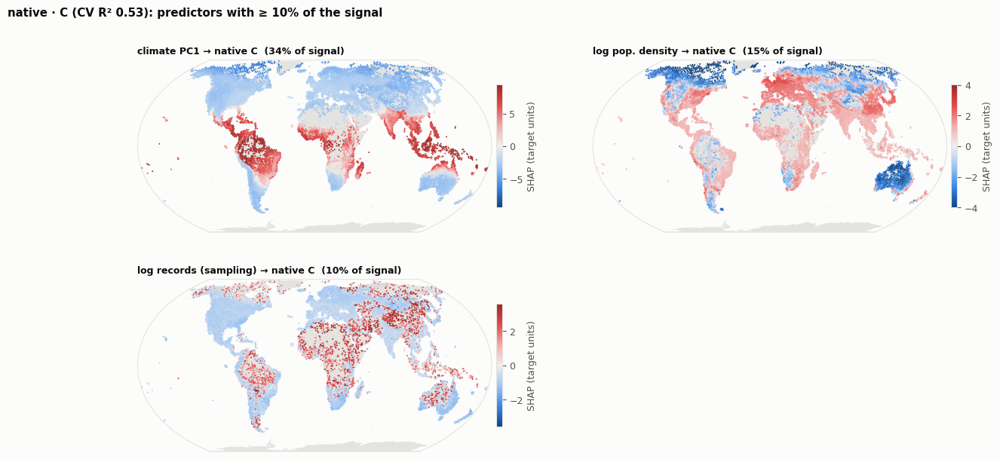

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


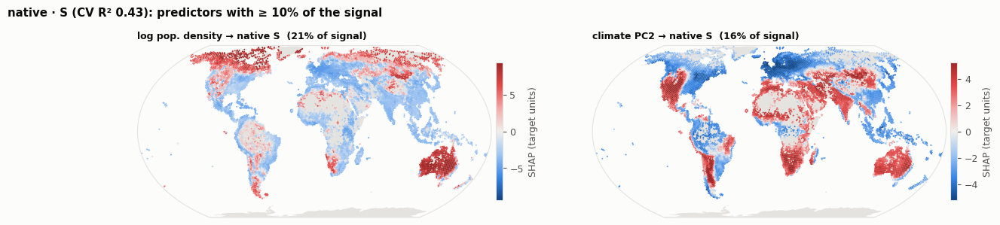

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


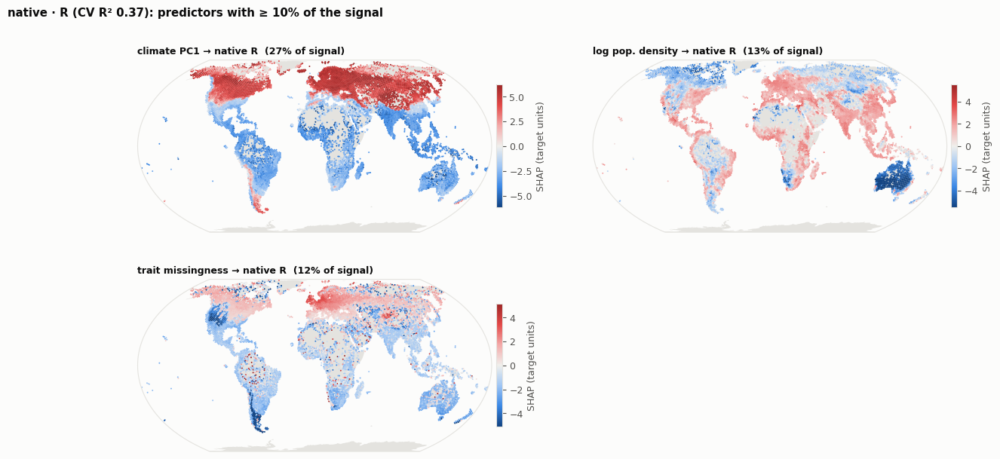

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


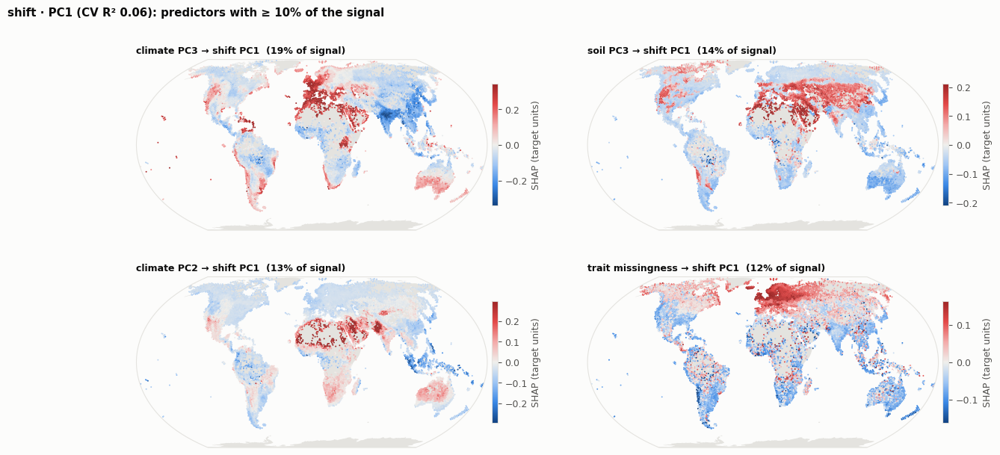

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


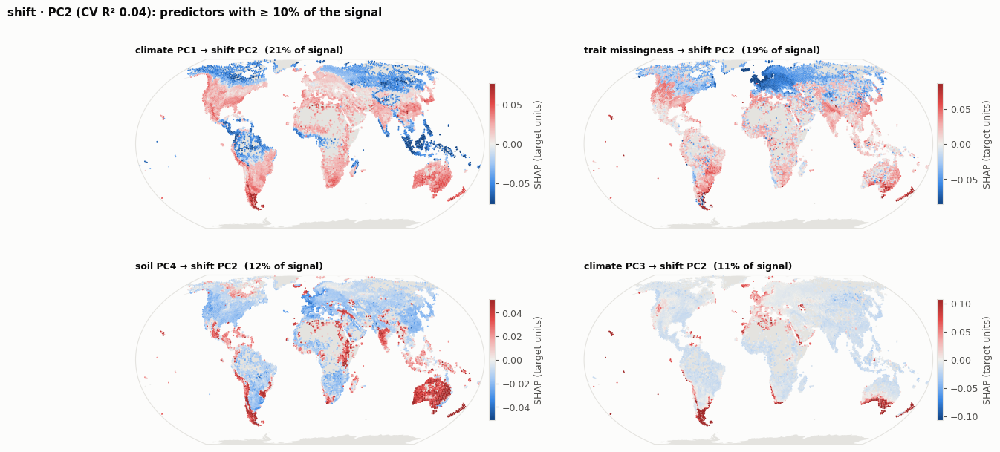

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


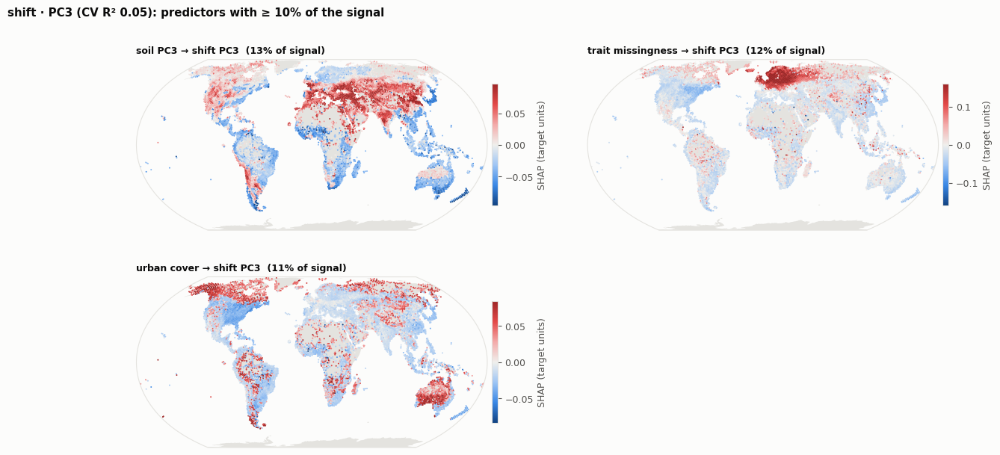

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


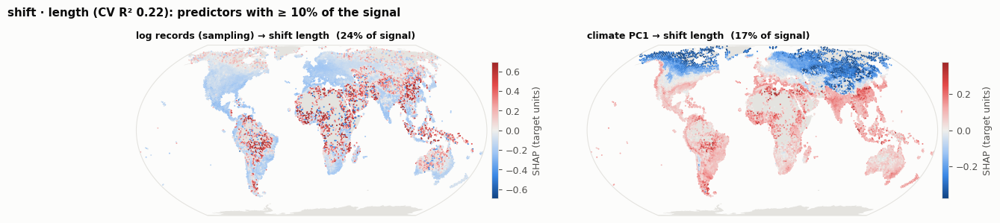

/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:245: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(multi_line_string) > 1:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:297: ShapelyDeprecationWarning: Iteration over multi-part geometries is deprecated and will be removed in Shapely 2.0. Use the `geoms` property to access the constituent parts of a multi-part geometry.
  for line in multi_line_string:
/net/home/swolf/.conda/envs/traitmaps/lib/python3.8/site-packages/cartopy/crs.py:364: ShapelyDeprecationWarning: __len__ for multi-part geometries is deprecated and will be removed in Shapely 2.0. Check the length of the `geoms` property instead to get the  number of parts of a multi-part geometry.
  if len(p_mline) > 0:


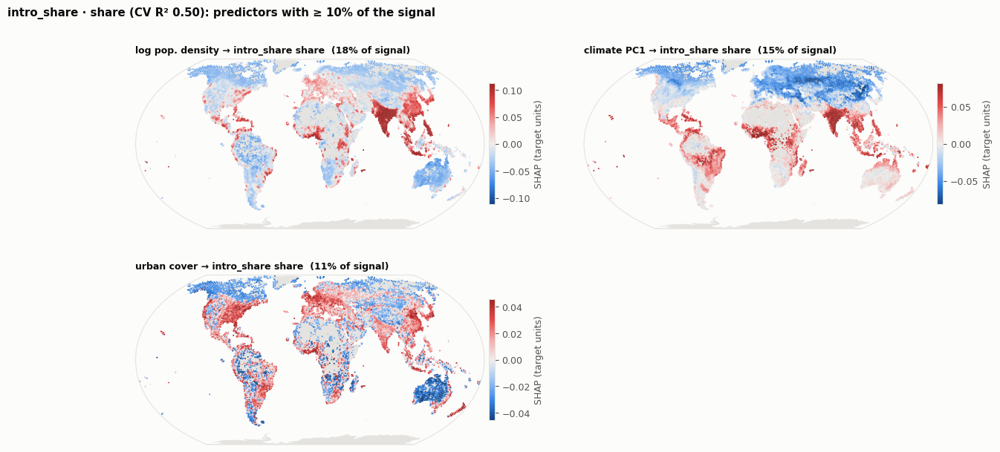

In [25]:
def shap_maps(pairs, ncols=2, shared_scale=False, name=None, title=None):
    """Maps of SHAP values. pairs: list of (mode, target, predictor), e.g. ("present", "PC3", "clim_PC2").
    The predictor can be a column name (clim_PC2) or its label ("climate PC2").
    shared_scale=True uses one colour scale for all panels, so effect sizes can be compared."""
    inv = {v: k for k, v in PRETTY.items()}
    pairs = [(m, t, inv.get(f, f)) for m, t, f in pairs]
    vals = [RESULTS[(m, t)]["shap"][f].to_numpy() for m, t, f in pairs]
    common = np.nanquantile(np.abs(np.concatenate(vals)), 0.98)

    nc = min(ncols, len(pairs))
    nrows = int(np.ceil(len(pairs) / nc))
    fig = plt.figure(figsize=(7.5 * nc, 3.4 * nrows))
    fig.subplots_adjust(hspace=0.25, wspace=0.08)
    for k, ((m, t, f), v) in enumerate(zip(pairs, vals)):
        r = RESULTS[(m, t)]
        ok = r["ok"] if "ok" in r else np.ones(len(LAT), bool)
        share = r["shap"][f].abs().mean() / r["shap"].abs().mean().sum() * 100
        lim = common if shared_scale else np.nanquantile(np.abs(v), 0.98)
        ax, tf = map_axes(fig, (nrows, nc, k + 1))
        sc = ax.scatter(LON[ok], LAT[ok], c=v, cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim),
                        s=2, linewidths=0, rasterized=True, **tf)
        ax.set_title(f"{pretty(f)} → {m} {t}  ({share:.0f}% of signal)", loc="left", fontsize=9)
        fig.colorbar(sc, ax=ax, shrink=0.7, pad=0.01, label="SHAP (target units)")
    fig.suptitle(title or "Where a predictor pushes a trait up (red) or down (blue)",
                 x=0.01, ha="left", fontweight="bold")
    savefig(fig, name or "08_shap_maps_" + "_".join(f"{m}{t}{f}" for m, t, f in pairs)[:120])
    plt.show()


# --- one figure per target: all predictors with ≥ MAP_MIN_SHARE % of the signal --------------
MAP_MIN_SHARE = 10        # % of mean |SHAP|
MAP_MODES = None          # e.g. ["present", "intro_share", "delta"]; None = all modes
MAP_SHARED_SCALE = False  # True: one colour scale per target, so the panels' effect sizes are comparable

for (m, t), r in RESULTS.items():
    if MAP_MODES is not None and m not in MAP_MODES:
        continue
    shares = r["shap"].abs().mean() / r["shap"].abs().mean().sum() * 100
    top = shares[shares >= MAP_MIN_SHARE].sort_values(ascending=False)
    if top.empty:
        print(f"{m} {t}: no predictor reaches {MAP_MIN_SHARE}% (largest: {pretty(shares.idxmax())}, {shares.max():.0f}%)")
        continue
    shap_maps([(m, t, f) for f in top.index], shared_scale=MAP_SHARED_SCALE,
              name=f"08_shap_maps_{m}_{t}",
              title=f"{m} · {t} (CV R² {r['r2']:.2f}): predictors with ≥ {MAP_MIN_SHARE}% of the signal")